# Robotics Week 5 — Motor Parameter Identification: M3 and M4

**Final analysis based exclusively on the nine newly supplied named files.** Program A identifies the model; Program B is held out for validation. M4 Program A is repeated for repeatability. All data are embedded in this notebook for offline/Colab execution.

**Battery:** 11.0 V before the experiments and 10.9 V immediately after the experiments (post-experiment measurement with the robot stationary). The measured change is 0.1 V (approximately 0.91% of the initial reading). Voltage under load and per-run voltages were not recorded. Voltage-based motor constants remain approximate and exclude motor-driver losses. **M3 = left, M4 = right.**

Run **Runtime → Run all**. Graphs and tables are regenerated from these nine files.


## 1. Read all recordings, verify their columns and durations

In [1]:
# Nine uploaded recordings embedded in this notebook (self-contained; no uploads required).
import base64, zlib
from pathlib import Path
folder=Path('motor_data');folder.mkdir(exist_ok=True)
embedded_data = {'M3_Real_A.txt': '...', 'M3_Simulator_A.txt': '...', 'M4_Real_A.txt': '...', 'M4_Simulator_A.txt': '...', 'M3_Real_B.txt': 'eNpNXEmSJCEMu89bqiMSs///YyPZMnBq1FlJsmMLmVGt/cr3+/4Npmxnqp3UOKldM1VKO8naT7Lf5LzJfZJWTg5m8yT7/e+8yV0yWYudZD0/qPe1el+rt5CtnBxaO1Vst2Rtj0z2cpP1vNb7+XCf97+3ZOO7zWTrJNv5xBgn37FOjed3k/e12e5/x8lhrpPD+m7STjVXO32xxk2uk9zf+e22U6HdTi12v108b3KfZPnsu+n2pPu66dtC5dt2h0p50vX+vvR50/NJ75u28qTr/a7d4VlsPOk71kq9g608w6Y846bU+YzjfdPP0CnNxk3fni1tPOl1y9DvdCrPWMLkeNJPW/Xn3XG7qozbV2W05//j+f+63xpPu82n3ebTbrM/6fmk902vOzjLstsmzzgrz0Arz0gr+7tl23dKlV3f5eD5/3zSt/z2Wbnp9qRv3e1bT/qOVXvWJnsWJyvj5lPWTdsts5k9C1R70s937Xm3Pu/Wp8z1zhGrd45YvfW1elcfa+VJ37Fqrd1323jSdwmyfuem9XbL028fWV83z2eM2Si33cbTVqM/6fmk97NUl3fZvuWZt39tzlueedcENOGTfuq77hyxdee1rbt22v6e9J2btp/+elY02/O227Om1Q/fHQ46AFb6ABMAMyPABsD0dICf11L0BP2L9UXvNG5R6CkHnU/GFBgAqwVAf1SM5gD4RDVLgO9gDARYBFhbHOwFsKKgDRWvKHYAjJiKHAKwCiyTg0owBFi2ugQ6n+woW8POVFsRwPpbWxVAgWvremcTqEH6hwyaGqTjXdRWgE3Vq36Gnqi9R+X4t/YpMPgOBr4DVnsUAYzoOlSCgVaqo0eLjoKPjqkn6PA6drQOmhRbf4kGQbFpB0QjIgcA9emAdVDn1M8WcptbAG1RlzKY6Nu6ahR0YjLX1fWEXb9m5DZZubWjppMtur8o6MQErduiQSbaHDuKAL6Hdo93FhtxK4OFRmyfRtWCLdA+i9wWurN9LarNkrRvRG5cfNu39DM0TCtfNOJC17SiDDa+04qqsAuBSrCN76gbN79j6saNJmumKuyBj5pKsCfBiO9sNGIzjeuNMdpqjOvJqrSwjAAwPBtnhwO0bKvDAmAfbWj5AJglMNAEUMmG8gTAEt9aE9i042JcT05ELI4zAH6O8VoDoLNaNwF+h4uiAxgcrQ89mXyy46PYt35NI3FyirYRs3HSAGlDpWbDtBGTaRpyxbwQ6DQsTe9gHLTZlBt+3qY+Spu2TVWbM7ktZUBjpa2yAmCQt1V3AJhMbfWoKVcX1DqyZmNiMgqwf3aJtq6Lxm2sb5P7TNs9PopxAxBDeTb2z1YG6Khf/2IuTM7+HhvvZJP32Hgn96AeG++kIQ1b5/M06tSLb2JI4zelNk9vmtZuRcP0QD7FLXWkJ9JudEz89tfNDS6kN9I1/m/8v2+ASCNP7ESexrLbzY0OpAfs9S/SGCe9mtK041t8CyO4V9+UMF35m6k08q878sTjHpsw0vgWRqqnWfem8qMTexh6k3sr7LkoMyYFHIV5024kTq51vY9x00v/R/7je9JWb7rZTY/n/+umMclu2p50e9J93fR80vt+d6m+nq7zpp931/Pu2vukd7n/D+NO6f6k5y3z3ic9vvKkUd+/oZYbH5pbiAMZS5sQJ8lOhL4aHGtCeEYzLxCaHvtFPuPKUbD1BOJ8gFUqhC1zWMmvcx+EBSfEBZ1eqSPMEKB5EPK0nYhzuWYujbscdmgh1gG7pRC3wzoSYWhip0/EknFmBnIP0lQHDsrBJTAQV8k21BLYbICWfum7PCatENd6TB8h7qWcFIG4prOJA2GoDxqIgbh7cIcOxHYZ2dawkn6+6f7Fyrbo3qrlYfYBZY2MCx5WbCEuPlj8hLiwoR0ToZwzy2JcAedKxG1tZY3II2CLVFuXRdTUm1xWsEkqT1r62BgTcRPm2A3E2m5TexbnN7J16TlgC1TrFrb1zjH4cavYOQY/TAtMQ9X9w9jF/pao08HPMchFFD9PhEaYZyR/qK1/NBCaa3Lz/otdtQL1JoQld+ZIHrQk0BwmhAJPMiuBMAPQqImQmDmSvdroqMwFAw6dIsR9ZOZIRj8S1SKEVzBothBaF3tPIvx70mYNhNbFkP2EnNSoiQqfNZWFVhCmiL5A38An01/aTpiEiTBpMF1VMkzjn0/zQI2/HIkwgbHw5S+xNM6+1Z6TtR1FaLC2mIBCyxmXRPDN59DowfhG66LfhFB8+DRqM8x8oCwLM585kmGA8j2NZEwo1HZlLlhVgTSrBm3juWoirHUzR/Lg3jVXtgt2sR889UTYK+e2fI/129m6ZLYm7be/NOjnXolQP5gdifC9RXc7EKwWTDh3HOlHLDncXI7WF45vK2SiwpFqyGaVEg7WZloED764ihxBTCGYueHYYaasIscXj5fJWccyuaxGGuvDokHlaZTVkqTh7+VEou6rig7DoF1VjiBaHSZ8/AYNteR8Gz655HzTCFsie+Bw/rCIWKTRErHvD65mqwVRZJP/jzLYIN8WdYfz/IO/6s6xYZSsXpXGu2IO4ZwjHXUnZ7VE9tCqXiIP4eQjbUobSTylkf9wm2dwzVwiEA1NvMQgGrbtJQrRUPQ1w3GPdPSXp1c4/ZEu9/erPun+pOdN7+/ms4NMinT0UaTnzT/2ek/v2OuVbuG2sQL7G+GlGGYwVqIhUH87nRm20S5ykdmQu2QGnU/ki3CrgTUSzhn7apPQCbBIeAqg4bfJqeXQ2CavuBa+s+W+Y2DtWtbx/zft7/D/kVuVT8oddNfZj5e/q3xSeKqkVkUtsARNLiUXyd3kFXMj3y0M+cEBCFexy5fHO13V5nDcXSVo/GjvctI7f5YZYDXePTPgR0dRBhjsWAdM7juaasgr7vjFHnJqYVsDbAF+dKZjjzbf09KXRwnoAMdKhY/Ks3H7Yc+VvjzeWepG0k0bc/748lueDbwq5MalLtZS5MY9O5ZZPkkvH7/Yu8ixZwdv8QzYUgBEvLD08GXio9h2AVQc2AM/+CkqD2cLkAnhs0CqErYgIjUxtgsilWmit2EShJuKLWoShceHzYy/zOFJQgFILbOMX08SiPONbLqeYTwCmZB/L3mgNZkLF5nYkJ2Fn3L6N/PMMcuNvHw5aEnxA4kM2pXvJRuEEUcUDuggSUY2X2iyLC1zWY7Ex+zNPN2gdbPFUbQutkY/B/i6vHy2Uk8CoPkzebK0iYBiCk0uAEBTaLIsYoYw9vh1DpYwxPg9DWLYS/zC6HLjvTfHTHff39tN/r75qYTQ4HuwhOX+8z2ulmFM8uuiiGB2Mpe5kwFgLiQskwIAihnpHACQasQ9C0g1IlcCFGybm8cFNqS+4KNnq0bVv7dVo1o4CvYUSeC9KbYIFhnPR75PNAF7s4gvmqQXgcLPrZjXAM7wOxtQWJSf2IBSSgm3/XPge88kFwjQ44n5E6ecJy0BgHBfeQSCV754wioXs3D8MeIBWgBUAGAILILw2dtiBsGcww1gQau8WDZEqXJjPxanjpIcAQ+PDkkAq/kLL9KYW5MLXZlBk9/vpW5yops/UQbNj5++Qw8AqASdpeaAdcAMaJCJFeCRlVxg/1n6wyzbKHKg+c6ox+sH6EFJDJY6yPTZvXXGHhdMeeOc9nBnXiCfOsCM3Kafmq11wZJbHaA+P1siMALMF+znnf1msOsLenlAjCqBfYF933qAveC45KyE8ahQsBAep5wNZkW+TLSslZqQXWClH2h+QJhOe/N393d9fwzM8l3nHzB9c+53gOmc0/3nKN7X/wdcB35++pj++WaZ63HQF3Ou8gIw1B2OJAi8CjW9a5qUmCHp0jauH9bSS2/VYbrppOc4nfLd4lDOAOYuYXpJmNcsVbpJk5YHYEuvfjgc+WOuxNYzK1K0mKpfvuttNSyfGnMeSdRUGAac14LchADXl6SAP01v2yYblqeRogX4IRQueQFWYfYkDbzLyFYF5NJucyf0PkqvCYt0J0wyguQAYA4z2oOASdqQ+MYql23lGwM8iXzq393Z7L6lwGFI6N/dK3mHz2GW6uN361cScqmtXz00gREeLmA4PGQA7HzAnbwB3ir1DP5PZ9gJ2fv1DP6PY7KWmZ49m71eSoC7ac3BP2gVAR5qgYt2zcGP3ZI55+AfPMAAXPmUvV/pagUs/G619OnZ+37yJNqArVFHwunvphPMfRKr+5eQG0nNwR+WUW0nK85QzKqR5AHL3Oa47AHgPvSBn+t/6euz92vP+vKgG7CN5BNYqqS/wuarlzXgrlFHuseTc7COLOT06o/j8nv1x/H5F8s8sr5jusIgsyKdC5iuNu1wwJo8AwchPFRVn7Yx4EpIo6fysEDkAt9d2Qs8xgBMOoO2OGBPtsGrv2ZCzv26NOr8rK7UfciIyqz2YSM4+OHaZM7e7MmJwbnwd3dCrCeYS5kVDw25SyfkqGuf76aDWzRAiE3oIAEEK8CdnPKLoCA46FucJaCBmF+SCtuBjtP9w0krcNA104E627wlscCaN5Omh9tFS2qBXkCzFIAQ1EdB0WoV08B3Uj9CO61VHXCzYZq0R1gdqBQJCQkzBQi1k6+OrTUBfxKn+rTsAZQB95DWi2gGvtNDUMBzYYAhwNbR0b7RmG/jC5fcazpMwMUqrSchARCqJLrDACEwIj1R0GcCLM4MNYR5U81ghWjeAYzygNUvWN8LMgMH7QXjBaHkCLC/7wH2gjof0F+QVQDAbt0fYC9oL9BhqFe1fzqP9SbpRd4mqZziZ1lDhA9QT96BuRR54N5lvehsndQCTcpE/KVlLhwQ3cQDkIkAkhtOKgJopxbhcwVRPWQEUIoWqiOd7pKbBdIRd+2OdsoOWL9WlCc3ZMz51Br4szgbxARjbVuqDYqjvcVKDFcwiYmormcSreAeQe/iFbhkA6lGzb/eVSP3A2CFSFrgXx86rnYrq4+W4gIjko6iu05q6Mib/AQscZ26d++xWZOUYHtO8TxubfaZ6gXuTnA49QU6Qp1ip1hRHYkVIJULFCfXWLf5hTWEuF32JX+efigcATFOw7++JWkY/nWupSk8AOpJUDDPndyC13arrSfbenziFib3xfGJFWDNgMQKkH0Bkj9P/xUoc+GoG8UkVNiO5M8v2nCjiOfgmQr9F3EL3ABH2alCmFSiqd9J1hTn74Kv8Gc9+QqW01LkwC3JqdaUIsApEifFs0MgzYfNHQdjVogbw6iSi9DvANLo2V7b9qUggXlyYQ0DiGVpOnR368gVLsd0GikWYLvCJ/skRKCtO7pO7p2vGJev8GdduXC+DwlZ/AAISEyD8xXofLEQnNN+OBD2I3MZOn8voeAL8tMPo8rQuPaDqjJEvPkhVvFTs0D+TPUrXF/ckAnbl/WbqUvwtl6SUxjXEPRw8BzmtV1NqPkvh1BnC9KCC0udzzSuw4xHv4nL4C42dpUkwWu7U6BQQokoxM0czkC77MWU2GXSYwKyFDY4Uv3oLxVvVfdsXNCYjAV/V0Ih4EsUmm0GY+FAhEN1sAKwV13W4R6YEQRfwPMnAOkcaK9MG+UwFqhpkBQcXF5RSRoA7DuMhUs0krGYqTRgt8+UGpCxmFXuvgsu49BhUjcFIPWAl7pJ8kCDcIZ5MN1Km02iB+5YsweB4l7w7CqOt+KhL/xnyT74z8Q+DJeC7pbH8NjFivgCfnSk78/WGe1SEXNIzsC5N8NwAJguJo2PeruFHHCSLQEQecAxO+d8gegLB0v1CWAvaC8YL5hvBmpeB1v1CVCfd3YQXAJvcZLLIFhfeYGtB7T2gHQxvRXWd+gHen6r5Ak41Q2AdiQMm7AdWAjnoS6oqi15lu7b3bKkH3zELEv6gUsXZbopgPj86WUyWAzLA3Vn21Y99AOn2arpBzt1seqhH4bDdPQpHgScR8HAQtb9SBjKamU91AUMvp3UBduqHcUBDeR1mIzK6bUukzFZ337oB2+6nmf0tfuPe0/qgqXqedbv1MW68gVvnJH0g1MXaxz6gd4blr+jZ2DOI+UiztiusdtDXayZh/VuR6+ZihFuiYApHWBwA2BqB4zr1Jrp6JP9R++Wo2tg41wmgzNoXSbDq4+sk7pwuA91wZx3ClCKV3/Xo25g9bmJirpgzju5NzpcgOIMgrrYX2ZFig4wK0i/DbB/qXFwOJLJYPX9FE/UxaD8+0tYXA2eJ9XcDgDVVti5+aGyDlfBrCw9XQoSAW0+XMW2dOUpZAQc+ZQHPZtnuhI4uPI8qQs3SXbydq4PAcys3JiBrdaTq2BWydsNmoJlt3TlKVkGtITcZHdrKZfgPrDbUSWQItots3JyYvdDMHBj3z0ryCEE2A450V0wnz+urp+/CgfCkW3lVuR+NA7MeRyCgfbnHodg4GTf4xAM3An3PAQDTZE9k2AY3r/z6CXMYYpThjf7nEf5wJznIRi82VdJyOG9V01IO2OvHAzU5AEmzdO9u1dqVJyc2DulLr6r7p0qFd9+d452Fy4zpsCSnGBWOdr9xBSDLLOi0wKYshl6NIAnK3wCMLiCZg5Ch0An374Srj4JCgDFUC1mkRFRWAkARDYMB1Lw9+nRDoeTAKiWnASA2AovgWXERiVQ2Ehhyas08ZjhAAqt+vhObStpCACpCZb/THICNAxsIxEHXtAmp3kyA4W8kGwAiHgT81J36QI6s+6lJaUAUA9xACCZQGOpu3QCjVn3K2iwb6SiYXiYh6QFfCepC2+DEVENPIcDEHFgzGB+Asxg2guaAAs6xwtUnwDSdURwSfA/AhGCItDfn80XvBns8gLJSgL0F6hBFMXSDuB58gOkLQnQXyDvz9BpxoNDoclImGQgsCPwWCX1Fx4lI4/LW78U+esUo1gpux82xHgCc/gP43HFkVoAJYuyHCWLsvj1Kj+f4hsrVX4+12OgDJcoLHUd64RiAK1UXGDIlfZJWMEhU6QMx7zxZzrl5tmnFfl7g7oMI98kjoPf6xl3sVnbbpJKwCCw0lsqL1iHPq4OAyjZEG+lnrET3i5DogZ+FyhzmY6GHY7D6IAdjsPK1Ok/OQ6eX9XDcQCluILToBx1BSdSkXB80Hq0Ig/PZRhG+1AcB/NMhQVNfCtHYvExlyXZC0vP4zLpKji5yhbnQJkbkDgHHmAat51f0thWJCEfjMsA2qnB+BhPpXbhhAQS50DTyexoKzgx7VNUB3cWsxy7jIM0y1AbHg8Zh9ZRYZglB0fmEUg6HB4VASm2A8Y347nEOSxFd0mhwdY160LY7IDE5FGFAaQYFR4h4bXSjwoDSFwT9yVmKXaCrWv1hFjw6zX5D65j1sQqUqLJ6LJUYfC95OBo/piHegXH4c80BnnIg0IrzuHj8m4Z6EAtKlDyHxy71pP/8Nr2laEX/mynCoO5jJIqDJZzSN1Anb95KFiYi/5MugSsQUQ7ozFYzinPnn0FlMxFYy6z7aPJAJrf0WQAZRiH11aMnGsygGwcTQaQYknM+3ZlVAX3Q1sKq/ANxA5z4X27Tchru1uyGnxvZ3CH9+1OFmWznDvWQXccGOsn5oJ9Wz+1EkcDUE9Nhv8ypBIkYjF2QmfAkQEQOoPKpq0liAceGwAowuJzEEIF6sgAQmfghkeNiFhX1QKE8p5+FkCXPmMRzJGxGxivoj44tmq1ntEbAK1l+Ib5uZ3YDoBQOjQvm6IkSAZj85BQgSOgNlEF7JDaxDXQJKlNXIOXuiX1wSehmXRHFkAZeCt2UQXVfzZ28iCModzJg6CD5Zs3/mwoWsQbfvSapAiAlA5cvurYlgwJJqkyoNVXpzLgPKyzHe6EwZoKDmHWcz0gYmQT2Ava94DxAmlHHGyJTwLYeEB7ctujP2DdDNr3jQc8JWhfe5+M9oCjaHBYDqXAqrdiySGwjVppT4QFA1Tn1VkApqKBJjpMgq9dsgIwKQXv42YnyMNjVy3dZA4EwPWEXWBZTBkCxwxghg1QbwaYcQOMWAQcB7KQdaUKgxPdY8rEXbCQLSkFsoOAJ8AjIm3nibiohMkhMBMuzyfKgjXqyWyQDwFMCQMNGcAkSXw1aCNFKJhUhPUIK1iM0VNYQXOgjXnICtZoHNLAv3v5B6/+THUAD6MA09Pn+R9gevpkhwBPcAbnWlsnOoMzFO5RQu+Fle3MgwDA7H1flVsq0mPJbldYMTw22Y7OglXYyU1RGw6YESMkBACzy8iTY3P7TvTFR2hHWDEJU7BDDQVgloqjHHAlZHf3yz80hzm8GYMB2I6wgjmXcaIwmFU5HAJ2cEZYJ6SZ280S0pXrSb4NGvaAKQfYzWGq990I6Dm8XVgBmC42RZyAh0Pg4O91nAgMf7pTHMF9s9OeEFnBCvJQTnQEK9hOhEbhu02N49IJbBVfEg5c4PvlH7yCvc0bewE4DjvBnPt6pBMYaidQg3O/j6zR5PDuJ8hiFodJGtAIBjykAS3HnmwbzErmPJM0IO0MmBV0g7TPfoIyWP2Znr6bsn2mp+92bl/lSCeGh8MnaeDVv1oJboT9aiWGv5syE98v+s5mp98AaBmr4f27e4oyjKXa2Qu+Q/a9jnRiMRL/mzdCgwKsldIJI8xeIHEKmIQS9QOAS+KJwTD+cJ55SgsQsRC+jo0S/r+vYqMopJ7GzShLoRoEplgK/3DezUJLf5iuIGCbj7xrgzV3GkHCeBsZjMHGH+9VCCPDMTjPRtVFCmyNUXUrAYfCSAZi82dNwgHOvtEkHKCxP5qEA8ufKMKBtszoCnEgazF0KQKpQYAUT/A7XdIFDuXRk89guw0pD7ymQ0ESnbmNVB7wnaEwCe+FoTgJb5DQcwbTMXQFB/c+cwdHwQ42Zn/BnA+Q/097ziVPF8j/D6DAlADzBW8G+81g1xcoOiWAxCAB1gUekXaBvaB/D5gv2Deuw3xRz8AOc3o6IzuA5FB6E0cEX3aFH2keysEl2IEWkRwnmrhAcuJ4SYK5ST9y4MxDR9BunUlHOEk2a83oD5alZmAIJ9A8dATtBD+eyGsebB46gkaSHzoGAeFIFIBPKT9CDMqBeSYB0fzr3TLygyW7BISjpA68BeW2DTdh5vhSVsHajrz+geN/jpaUA783JBFwK8rD2ZIjBZKj3f3rs6Ssgm025a67pT1nT5GFP5OjzRJSp6k8J9tlZbyIf31ZEhCs7epJOTCXJRd5+KUgK69ioG00FcA+SKYAZZxH92dNQgouynNLGsIYEIpE9YzL+TqhHtzq1gn1YE+vDEJyAmJ9Coxgrel5rktArE8UgG96q6hkNKqA8pqI5ZeZ9H5EFkASLyz29Lp0BJGJAvAtetm56oGltp5BIcwlR/Ia/t7OMJCPF6ZkLlzHV00igcvoSmKNLUl5rOQRXtsah/toJH49RzIZcyC1EnWv9LOFOMdWO9c++LOkI7y2LYkEr21PIoHGzepJJHAerT4eAmIdOoIzfI0kNeiSr5GkBo2+NZLU4CxeQ3IFcu5AkisUbrZryunnOgP03AEBpFskuOoA5TUS3pt5IwOdGmxqX8oq+N7KSx04c1ZeysATPaCeQSH+TLcq+Dq41hbivPUTurDTHdXvEhBrt5RVME9FMHlgLtDKEJHJi2/OZRGbSCXzLXd/LWUVlUj18117a1x70C5GUhy0M1wcoCgqpBModMM/lkqK4kBKCvJK2z5REA7C9SR/BRDah8YZs0NbGazDjou5ppOjO27mcjkDQBAAPJoGEINA43/XvCuCZatbsR/8TpPYwMuW4gmyQLvJe+b82k0MAoffbhIbsHd2V6QCN+fdJTagt7K7Ak44CXd/fP499FF24R5SBHDd3ymR8JoOkQZ0SPeJ8OA7T4QHgFgHLt07WYcAknx4U82rsSA3VR9gL5AmIcB4wXp+tnVzRABpRgJIwhKgv2C+YB8A/7SUB9QX9O8BYzzgFqd+JQPoWXHA+gSJAB6aYPAapnJvg+DlTWU/Wgo4VekYs+MA05vl1gqYNwNwRQJcJyqkEJ6s4lqokxUvHvpqTfg5TOUBN1Yq/RMu1qimXICbf/3auRnCq9Dq0VI4TM+fBi7gCRLhdUNf/76rpQAsR0vh11XVQ0+wzD25DHKJ1U/ZxFb4uykXoDYahno50gr+eGRb+dVV30hVCg8gAc9lE8YajfSxqxdjfoet4NM8MJ7mjTPzegZyq4x7yKe8/OqbKReAh8VrtpJC4uk+YAbF8LQKMFUp5q2xzrUTvLTpW+tIK1jBnRQSpRWAqf8o3im7PtKK6qdxYiv4oXPhQ/GRs7NDi1//9ZUjrTDCbDrauZURkpe8qOXSE7zSq3ypwuGpB28Sa/f2CMAkTXh9BGA2HYWfgKnC+SpzLql3YeBJZRRWkhedl2UeToGDgeFGNyqkMrDnKi0Al13yojKUJcmL5jec5bvVYT1RIax+zeiM/THnmnEBDHqsjBO4USHkuo/wgqVqqQBgVwJmNMry+9PafKJCKnXgNyoEI+9cU+HN3mtCb/acCx6jC5hZ0XqtJeeC3zlSS84FF9ZW6lAvl1Ep97xKC97qtm4YSC0Z5eRKi0q54eUyGJrzcBm1XLbCu/uyFZ1VuGyFd/fKCnJuVkq0kstgjVb/7h0TgPOEgbCQl61YzGp/+3IZjBDal8sAbPuGgVQP7TtKi+rBfUdpUSl6uHdNVMoRksuYfrHd4TI64WEr2N08NU+lBbNKbm4wAq5aRnhwjlkyFuZPQrHAhbRaRKD6pROVB4vJZVSe8yWXUc/FjVzseJoVXIYDXVXJNucJzi9v7+NRStAXg0A3TnKuWc2rBJl11T2lxd/RZYLsBWu6SZFD0FoNX5nzz3RPKM/EqyVj4QVNAQXXg7zGkaEA1boyGP5EfAFXa+sSHHgz9rgykz4wPFcRDp0ZPIwFLxM8sRI1r3NkIzHoq6Uco1rYJ+7HV5tSLFSWQFc6mrfO1FUYvGbQDmPBBll52UP1SwvbA5JwcJB8gYNdLthJODiwF7QXvBnsFJFUXo74lQfYC1p7gIJuAiTlQVDcMPwPM46S8A==', 'M3_Simulator_B.txt': 'eNpd3Vty7DgORdH/HktVBHHAF+Y/sZacBLhVXwaiWzyKW4Yy7WUy2z/e/mn/a//035fx+zJ/X9bvy/59id8Xa+erna86X89Kdpays5adxeysZmc5O+vprKezns56OuvprKezns56OuvprKeznp/1/KznZz0/6/lZz896ftbzs56f9TzyX+Z8Pev1s17Pf7mzXj/r9bNeP+v1s16P/Cc+X89646w3znoj/1Oc9cZZb5z1xllvRP63Ol/PevOsN89686w387/tWW+e9eZZb0b+Rz9fz3rrrLfOeuust856K79ZznrrrLciv3vO17PePuvts94+6+2z3j7r7fzuO+vtyG/D8/WsF2e9OOvFWS/OenHWi7Ne5Lfz/X7OIr+jW35Lt/yebvlN3fK7uuW3dcvv65bf2C1qQrLIlWtYalpqXGpeamBqYmpkcmYsh8ZUU5gr59xYDo7l5FiOjuXsWA6P5fRYjo/l/JjXgOfKOUKWM2Q5RJZTZDlGlnNkOUiWk2Q5Stbr2ZEr5zRZjpPlPFkOlOVEWY6U5UxZDpXlVNmox1KunINlOVmWo2U5W5bDZTldluNlOV+WA2aznni5cs6Y5ZBZTpnlmFnOmeWgWU6a5ahZzpqtepjmyjlulvNmOXCWE2c5cpYzZzl0llNnOXa26zmdK+fkWY6e5exZDp/l9FmOn+X8WQ6g5QRa1EvAfQ3IIl8FcgaVM6icQeUMKmdQOYPKGVTOoKxeXnLlnEHlDCpnUDmDyhlUzqByBlWvW/XCdV+5cuV67aoXr3r1qpevev2qF7CcQeUMKmdQXi+KuXLOoHIGlTOonEHlDCpnUDmDyhlUzqB6vd7myjmDyhlUzqByBpUzqJxB5QwqZ1A5gxr1Up4r5wwqZ1A5g8oZVM6gcgaVM6icQeUMata7hFw5Z1A5g8oZVM6gcgaVM6icQeUMKmdQq96A5Mo5g8oZVM6gcgaVM6icQeUMKmdQOYPa9d4mV84ZVM6gcgaVM6icQeUMKmdQOYPKGVTU26b7vimLfOeUM+jvDM5f1f8qf6pR1fyr4qlWVfuvsvmUUeU7jE+p56J3HLPUr3wuM7/lSXovG7f8ZXU95brlL62/l0WV+qWN5zLZLX9p87lMfstf2nwvG7f8pa3xlOuWv7T9XhZV+i9tP5e53fKXFs9l7rf8pT1vNJ56oJ6n3k+9UJ9/TXuvjVv3X+bz4v/Uhlqnfq7tjvrk+nvtQH1yuz31Qn1y+3tt3Hqc3PFcOwz1yZ3PtePkzvf/31EP1Cd39adeqE/ufteJW8+Tu59rp6E+ufFcOx31L/d5VXnqgXqeej31Qv3LfV4Qnjpuvc73rZ5rl6E+37l6rl2O+uT6e+1AfXL7++PGQn1y+3tt3Hqf3PFcuw31yZ3vjyuO+uTO99qB+uSuZ9r2Qn1y93tt3DpO7n6uDUOdk/pcG476zGp7rx2o56mfuYuF+pf7jPtTR9W9/XLfoenNUOvU86kd9cn199qB+uR6PPVCfXL7e23c+jyXnu/ZpzbUJ3c8155H06/OZ9N77UB9cpeeeqE+ueu9Nm59nlDPf5+nNtQnN55rz0PqV5/ceK8dqM9TsY2nXqjPc9Hea+PW51n13MtTG2qdR+pz7Xlc/epf7vO/P/VAfXJ9P/VCfXL7e23c+jyv+niuPc+rX31yx3PteV796pM732sH6pO77KkX6pO73mvj1ud51fdz7Xle/eqTG8+153n1q09uvNcO1L/c0fpTL9S/3GHvtXHr87wa9lx7nle/+pc79Fx7nle/+pc7/L12oD65vp56oT65/b02bn2eV2M8157n1a8+ueO59jyvfvXJne+1A/XJXe+vMxbqk7vea0/u7u+vOlAb6pMb769DHPXJjWed87z61b/c2Z4ZPM+rX/3Lff8p+3le/dXneTXtufY8r351vtY/14ajPq/2/l47UJ/c551GP8+rX31y+3ttVD3O8+r9TzXO8+pXn9zn/cb4/fzyKeMp+y3HLect1y33LaPK3w82v9JuqVveNLtpdtPsptlNs5tmN003TTdNN003TTdNN003TTdNN003zW+a3zS/aX7T/Kb5TfOb5jfNb5rftH7T+k3rN63ftH7T+k3rN63ftH7T+k0bN23ctHHTxk0bN23ctHHTxk0bN23ctHnT5k2bN23etHnT5k2bN23etHnT5k1bN23dtHXT1k1bN23dtHXT1k1bN23dtH3T9k3bN23ftH3T9k3bN23ftH3T9k2LmxY3LW5a3LS4aXHT4qbFTYubFpU2W7ul3VK3fNL+Pc+Y+T5NbjPYzGzeJ9Jis0/zPMjm+1yp5n2y/HseffN9ttxG2by/b3Y2eQd6Fxhs8g6eB/K0xSbv4H1yWqBR3sHz0J8yNucO3peJKWfTs3kXGGzOHbwvRVOLzbmD94VsKtB4y+b9TbqxyTt4XiCnO5u8g/EuMNjkHTwvwtMXm7yD/i4QaHrewfNCP7uxyTt43hrM7mzyDvQuMNjkHTxvP2ZfbPIO7F0g0Iy8g+ctzhzG5tzB+6ZoDmfTs3kXGGzOHbxvvOZYbM4dvG/V5gg0s2XzLDCNTd7B83ZwTmeTdzDeBQabvIPnLeeci03eQX8XCDQr7+B5WzuXsck7eN4Iz+Vs8g70LjDY5B08b7bnWmzyDuxdINDsvIPnDf3cxubcwfsjwNzOpmfzLjDYnDt4f8yYe7E5d/D+YDJ3oImWzbNAGJu8g+eHnxnOJu/gfVbFYJN38PyANWOxyTvo7wJxm9XyDp4f4lYzNnkHz499K5+JvybvQO8Cg03egV7tWmzyDuxdINDkM/H98XXlM/HX5B2018yczbmD90fklc/EX3Pu4P2heuUz8dfsbN4FAk0+E98f3Fc+E3/NuYP3R/2Vz8Rfk3cw3wUGm7yD0Z9msck76O8CeQf9DwDZGJu8A38WyGfir8k70LNaPhN/Td6B7GkWm7wDexcINPlMfH9Zs/KZ+GvyDtqzQD4Tf825g/cXQiufib/m3MH7K6SVz8Rfs7N5Fwg0+Ux8f0218pn4a84dvL/YWvlM/DV5B/NdYLDJOxjjaRabvIP+LhBo8pn4/oJu5TPx1+Qd+LNAPhN/Td6B3gUGm7wD6WkWm7wDexcINPlMfH81ufKZ+GvyDtqzQD4Tf825g3ivH6hP/n5mOR+If/VJ3++1cet8Gq7n2nwY/tX5zuS5Nh+Ff3W9L3nqgTpfD58JzsfgX53P4ffauHU+A/tzbT4C/+p6Aj61o67Zf+qBOr/rn7nNh99fnf/a77VR9c4nXzyl3TJTn/LvXeenSFBPJ9vpZLvVX3QkqqeTbSumT6dPJ9vpZDudbKeT7XSynU6208l2OtlOJ9uqvwDIldPJdjrZTifb6WQ7nWynk+10sp1OttPJttcfF+TK6WQ7nWynk+10sp1OttPJdjrZTifb6WS7198t5MrpZDudbKeT7XSynU6208l2OtlOJ9vpZHvUn0TkyulkO51sp5PtdLKdTrbTyXY62U4n2+lke9ZfW+TK6WQ7nWynk+10sp1OttPJdjrZTifb6WR71R9y5MrpZLv+NqT+OKT+OqT+PKT+PqT+QKT+QqT+ROT+jUiunE6208l2OtlOJ9vpZDudbKeT7XSynU62o/785P79SRb5FyjpZFFOFuVkUU4W5WRRThbXyeI6WVwni+tkcZ0srpPFdbK4ThbXyeI6WVwni+tkcZ0srpPFdbK4ThbXyeI6WVwni+tkcZ0srpPFdbK4ThbXyeI6WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFnCygJMFnCzgZAEnCzhZwMkCThZwsigne+vrZAEnCzhZwMkCThZwsoCTBZws4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFnCygJMFnCzgZJFO9rxnDThZwMkCThZwsoCTBZws4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFnCy90/WCseexthcKnsaZ3Ox7GkGm8tlT7PYXDB7mkADMnsaY3PR7GmczWWzpxlsLpw9zWJz6expAg3w7GmMzeWzp3E2F9CeZrC5hPY0i81FtKcJNGC0pzE2F9KextlcSnuaweZi2tMsNpfTnibQANSexthcUnsaZ3NR7WkGm8tqT7PYXFh7mkADWnsaY3Nx7WmczeW1pxnlaE8z2Sw2l9ieJtAA2Z7G2Fxmexpnc6HtaQabS21Ps9hcbHuaQANuexpjc8HtaZzNJbenGWwuuj3NYnPZ7WkCDeDtaYzNpbencTYX355msLn89jSLzQW4pwk0ILinMTYX4Z7G2VyGe5rB5kLc0yw2l+Ke5lqcGTDODBpnBo4zux73n7p+Z292Sc7smpzZRTmzq3Jml+XMrsuZXZgzuzJndmnOzJBryDXkGnINuYZcIVfIFXKFXCFXyBVyhVwhV8h15DpyHbmOXEeuI9eR68h15DpyO3I7cjtyO3I7cjtyO3I7cjtyO3IHcgdyB3IHcgdyB3IHcgdyB3IHcidyJ3IncidyJ3IncidyJ3IncidyF3IXchdyF3IXchdyF3IXchdyF3I3cjdyN3I3cjdyN3I3cjdyN3I3cgO5gdxAbiA3kBvIDeQGcgO5F/xMV/xMl/xM1/xMF/3+OqifiexnovuZCH8myp+J9Gei/ZmIfybqn4n8Z6L/mQiAJgqgiQRoogGaiIAmKqCJDGiiA5oIgSZKoIkUaKIFmoiBJmqg6XLgb1PFp7NPBxE0kQRNNEETUdBEFTSRBU10QRNh0EQZNJEGTbRBE3HQRB00kQdN9EETgdBEITSRCE00QhOR0EQlNJEJTXRCE6HQRCk0kQpNtEITsdBELTSRC030QhPB0EQxNJEMTTRDE9HQRDU0kQ1NdEMT4dBEOTSRDk20QxPx0EQ9NJEPTfRDEwHRREE0kRBNNEQTEdFERTSREU10RBMh0URJNJESTbREEzHRRE00kRNN9EQTQdFEUTSRFE00RRNR0ZyqaE5WNKcrmhMWzSmL5pcW/3ZPzU+3Ph100Zy8aE5fNCcwmlMYzUmM5jRGcyKjOZXRnMxoTmc0JzSaUxrNSY3mtEZzYqM5tdGc3GhObzQnOJpTHM0vOa6/LWeXGc2JjuZUR3Oyoznd0ZzwaE55NCc9mtMezYmP5tRHc/KjOf3RnABpToE0J0Ga0yDNiZDmVEhzMqQ5HdKcEGlOiTQnRZrTIs2JkebUSHNypDk90pwgaU6RNCdJmtMkzYmS5lRJc7KkOV3SnDBpTpk0J02a0ybNiZPm1Elz8qQ5fNIcQGkOoTQHUZrDKM2BlOZQSnMwpTmc0hxQaQ6pNAdVmsMqzYGV5tBKc3ClObzSHGBpDrE0B1mawyzNgZbmUEtzsKU53NIccGn9yqX1S5fWr11aT7P8VLUFtPba9tps22u3ba/ttr3223a7W0xrj2ltue13h3ptuu2167bXttte+257bbzttfO219bbrruPtTJq922v7be99t/22oDbawdury24vfbg9tqE22sXbve7WbYyaiNur524vbbi9tqL22szbr+7ce923Lsf927IxY7cyrh7cu+m3Lsr927LrX25vTbm9tqZ22trbq+9uX3cbb+VUdtze+3P7bVBt9cO3V5bdHvt0e21SbfXLt1e23T7vHuLK6N26vbaqttrr26vzbq9duv22q7ba79urw27vXbs9nU3MFdGbdrttWu317bdXvt2e23c7bVzt9fW3V57d3tt3u377pKujNq/22sDb68dvL228Pbaw9trE2+vXby9tvH22sfb427Fxl7sqmo3dm2oHyWkNopIbZSR2igktVFKauMyqY3rpDYulNq4UmrjUqmNa6U2LpbauFpq43KpjeulNi6Y2rhiauOSqY1rpjYumtq4amrjsqmN66Y2LpzauHJq49KpjWunNi6e2rh6auPyqY3rpzYAqDYgqDZAqDZgqDaAqDagqDbAqDbgqDYAqTYgqTZAqTZgqTaAqTagqTbAqTbgqTYAqjYgqjZAqjZgqjaAqjZSVd83SgOsagOuagOwagOyagO0agO2agO4agO6agO8agO+agPAagPCagPEagPGagPIagPKagPMagPOagPQagPSagPUagPWagPYagO7Em2AW23AW20AXG1AXG2AXG3AXG0AXW1AXW2AXW3AXW0AXm1AXm2AXm3AXm0AX21AX22AX23AX20AYG1QYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdmKHo00K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7KTATgrspMBOCuykwE4K7EyBjb+jX8TG2UBgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZRYBcFdlFgF9T1W19JWRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2A2B3RDYDYHdH4HdH4HdV2D/TuGan259Ogrs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs/gjs5oZM2x+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+B3R+BjY/Axkdg4yOw8RHY+AhscHOnxUdg4yOw8RHY+AhsfAQ2PgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/AxkdgowT2/eVRfAQ2PgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/Axkdg4yOw8RHY+AhsfAQ2PgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGxTYoMAGBTYosEGBDQpsUGCDAhsU2KDABgU2KLBBgQ0KbFBggwIbFNigwAYFNiiwQYENCmxQYIMCGxTYgMCqXYFVuwKrdgVWLd31U9VBq/ek1XvU6j1r9R62WqetNrsHudZJrnXgaqsTV1sdudrqzNVWh662OnW11bGr7Z4XXgevNt3TYiujzl5tdfhqq9NXWx2/2ur81VYHsLY6gbXVEaytzmBtfo+krYw6hrXVOaytDmJtdRJrq6NYW53F2uow1lansbY6jrX1e+5tZdSJrK2OZG11JmurQ1lbncra6ljWVueytjqYtdXJrG3cw3Urow5nbXU6a6vjWVudz9rqgNZWJ7S2OqK11RmtrQ5pbfOe4FsZdU5rq4NaW53U2uqo1lZntbY6rLXVaa2tjmttdV5rW/eY4MqoI1tbndna6tDWVqe2tjq2tdW5ra0Obm11cmuro1vbvmcRV0ad3trq+NZW57e2OsC11QmurY5wbXWGa6tDXFud4triHniME4+rqjOP6zhlK4GVlcDKSmBlJbCyEljZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVjZFVgZBFYGgZVBYGUQWBkEVgaBlUFgZRBYGQRWBoGVQWBlEFgZBFYGgZVBYGUQWBkEVgaBlUFgZRBYGQRWhn2tMgisDAIrg8DKILAyCKwMAiuDwMogsDIIrAwCK4PAyiCwMgisDAIrg8DKILAyCKwMAiuDwMogsDIIrAwCK4PAyiCwMgisLAV2/h1TLjbO5gqsDAIrg8DKILAyCKwMAiuDwMogsDIIrAwCK4PAyiCwMgisDAIrg8DKILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFZKgbW/azabQAOBlSCwEgRWgsBKEFgJAitBYCUIrASBlSCwEgRWgsBKEFgJAitBYCUIrASBlSCwEgRWgsBKEFgJe2AlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKwEgZUgsBIEVoLAShBYCQIrQWAlCKwEgZVDYOUQWDkEVn7V9T91SYr8Cqz8Cqz8Cqz8Cqz8Cqz8Cqz8Cqz8Cqz8CqzckGvINeQacg25hlwhV8gVcoVcIVfIFXKFXCFXyHXkOnIduY5cR64j15HryHXkOnI7cjtyO3I7cjtyO3I7cjtyO3I7cgdyB3IHcgdyB3IHcgdyB3IHcgdyJ3IncidyJ3IncidyJ3IncidyJ3IXchdyF3IXchdyF3IXchdyF3IXcjdyN3I3cjdyN3I3cjdyN3I3cjdyA7mB3EBuIDeQG8gN5AZyA7lXYNWvwKpfgVW/AqtOgVWnwKpzD6w6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVa9BPZ9we4UWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtBgdWgwGpQYDUosBoUWA0KrAYFVqME1v6u258u2FFgNSiwGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoN7YDUosBoUWA0KrAYFVoMCq0GB1aDAalBgNSiwGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoMCq0GB1aDAalBgNSiwGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCKwGBFYDAqsBgdWAwGpAYDUgsBoQWA0IrAYEVgMCqwGB1YDAakBgNSCwGhBYDQisBgRWAwKrAYHVgMBqQGA1ILAaEFgNCKwGBXZCYCcEdkJgZ7krq/o4w3Y/9bg+0LAEdpbAzhLYaffjEuvzEktgZwnsLIGdJbCzBHaWwM4S2FkCO0tgp+5nMlZGCewsgZ3305tLYGcJ7CyBnSWwswR2lsBOvx/8WBklsLMEdpbAzhLYWQI7S2BnCewsgZ0lsLPfT5esjBLYWQI7S2BnCewsgZ0lsLMEdpbAzhLYOe5HWFZGCewsgZ0lsPN+Qub9iMz7GZn3QzLvp2Tej8nE52RWxv2kzPtRmSWwswR2lsDOEthZAjtLYGcJ7Fz3wzgrowR2lsDOEthZAjtLYGcJ7CyBnSWwswR27vuJn5VRAjtLYGcJ7CyBnSWwswR2lsDOEthZAjvjfqwoPle0qvpk0RLYdQV2XYFdV2DXFdh1BXZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdkFgFwR2QWAXBHZBYBcEdlFgFwV2UWAXBXZRYBcFdlFgFwV2UWAXBXZRYBcFdlFgFwV2UWAXBXZRYBcFdlFgFwV2UWAXBXZRYFcK7P67ZrOBwC4K7KLALgrsosAuCuyiwC4K7KLALgrsosAuCuyiwC4K7KLALgrsosAuCuyiwC4K7KLALgrswh5YLQrsosAuCuyiwC4K7KLALgrsosAuCuyiwC4K7KLALgrsosAuCuyiwC4K7KLAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuzGHlhtCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuymwG4K7KbAbgrspsBuCuwugf27prMZbCCwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwIbFNigwAYFNqCu3/pKSkBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILBxBdbbFVhvV2C9XYH1RoH1RoH1RoH1RoH1VgL7PCi9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9cQ+sNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsNwqsGwXWjQLrRoF1o8C6UWDdKLBuFFg37oF1o8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1o0C60aBdaPAulFg3SiwbhRYNwqsGwXWjQLrRoF1o8C6lcDq77r+6cang8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1o0C60aBdaPAulFg3SiwbhRYNwqsGwXWjQLrRoF1o8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1g0C6waBdYPAukFg3SCwbhBYNwisGwTWDQLrBoF1g8C6QWDdILBuEFg3CKwbBNYNAusGgXWDwLpBYN0gsG4QWDcIrBsE1g0C6waBdV2BdV2BdV2BdaW7fqqjP64UWFcKrCsF1pUC60qBdaXAulJgXSmwrhRYl1WGVYZVhlWGVYZVhipDlaHKUGWoMlQZqgxVhipDleGV4ZXhleGV4ZXhleGV4ZXhleGV0SujV0avjF4ZvTJ6ZfTK6JXRK6NXxqiMURmjMkZljMoYlTEqY1TGqIxRGbMyZmXMypiVMStjVsasjFkZszJmZazKWJWxKmNVxqqMVRmrMlZlrMpYlbErY1fGroxdGbsydmXsytiVsStjV0ZURlRGVEZURlRGVEZURlRGVEYKrHsKrHsKrPvvZ9j/A6dMG0s=', 'M4_Real_B.txt': 'eNpNnFuy5SAIRf97LOdWRXyA859Ys2GjfnS16ybxGOMDtqj0Lb/Wft8/Qaqf1NiVWqNSdlLtu0m5ydFPctpJ6smq7ZMU+U5y3OS8N6iepP87Bbxl7fMk5zpJvcl9chjt5Dv6Kdm4hRy3kOM+Ntv5idnPu815k3qT+yTXd8qwZN56vMl1k3bKoN8pg/abvFWidirKvpu8hbRbSJunomydHOz+2v5uUs4Ne9y/6vmJbfcTfve59sl6WsT9+N960vak972/3WK31p/0fNL6pJ9npd08pX9PU7xlk/Xc/5Shf09a5KZvK/Ti3Pfttx22vm/+oz3p/qSflj9uY2xj3/xne9JP+ed80sueznT72HrKv54yrKcM6ynD0if9lF/bLZs+9a/z1one5u29+KbtKb89/d/Gk15P2m7+T7trW5708+x+6n/fRu/Dxx0evlt++W67l28+6duE5bttWNotgzR50uNJrzv+tFt+H7eetDzpccsj991F7rfzpnrv77fvSL+dVfp6/n67qw+S9+/j1rmM2++8CDefYTc9v2eEvW1e5njS67nnjoY+It96eNqbPO1NnvYmT3uT9XwvbU+63zz1jt0+5N/30n3T9kwW9swW9txvz/37jg+yb/+SPZ/00zb2HR/6993JBu1qBXSHWTAdtBHMwbs2YHzNJyhvWwnqIISGqcvn1ITtsAjeDHrbmdvw3+vSCMNzw+iW4L+D4S3Ah0hvPpqw8Iw30ADFvPgRvAX0LgVenD4kYQNm5ja9YXWMcgFe0z4SToL/6JB87dkB3kkD/FX6WJnbnADjbV6tfX4EA1QG/pJ9joT14crKN10NV4yAEqyP4AZJXy2rannp++oE/xp9TYL3t74sq2r5pNH1I3jv69ry5VbYBz1Lrfg+yjrAHV4FBLy2+nQT4L/XrRG8/XTrmZt66btNAiretADP7Kwq9cbR95cFNbQQTLcBaBSbjcL8O7nBkmWz7p9kb4JX2fjYqmwOB8mszc2I8fGTmD/rHy5LYIZnNEuNkoyP77P90wyfcBMagE1se66jTYLPCKMpYSgsqPwk2+t6+MiX4HXtgxHBAGwU25vYkPym3qdwZWuCT/yjt5kggPwk3t0AWSH98/F09EXw9/JJluAz4xgfwb/6GFKwHQZ/ZwNWvKmbjbjNCNLc9vtGQochKAQfXMYcWWrUhXe1LKjPtQ5KQF3PTUAJFouDWvJ+ER+r+xzlwOL4ROOw8hlBCZYRUALNLuN93N9U+T4+KDsM3rYAKwsK63ioEbxvD8su0/0DOUh8OR8KvKqsZ3G8cA7ZZbqTgxLwo/vjbd4nxuYreEdy4CfxfgDrmFn764+djbxjcpofv6m3DoeYljq+jA8wX6S9cucX00P36vf0ZtrvaS3T/m1ni+nBCzVhgWfaYI2HOehp3L8z7W87fd5GGqOODzZM+z0+TEXayzUlTBlP4++7Rdo/+kyHomOomz3s4D47/p6/O70o/i/zQfk7n/XXmxjVI+1lGJ1/9/zHzDTecYQZ52kv/zCm/dn5Me2/Nfm7/rWd9abrWaTtptf3pOVJh4fB9HrS1k9avyctT3qMm15P2tpNhwme6fQ6mO7P3+eT1vteO0wQpuVJ91v+PeWm9Unvk/aJod20f5y/dcjbLQnDif92UjTefcgbbPPfT8JQ7lZ6kfcgmH1JPjG7vSNF3urlK8L4KScXn0mW22pFuNMLFDQwavpUQTJ4hLsIoz06ZRJ6dq9cfBByqjcaGAK6FvkwuWBrJKGc4+SCqW6cXNClfdRK8hnFydtyEkZT79okzH2zHfJ38O5AwjQ9J38PturypkPCWOkfl4RxC7P5X403CzN4EkbINetO1NJSksCAgiechFkD03MSLC31aSLJh5KFETEJs5WuItgWaK9JsN206jomLEzjSRiprN4PFr3bCazBhiHNFssCy98LxucaJvj98feaD8huUnQSJoo9imCmbC0SPLfrOS+GflUWd6KdBsvyuaWp32RZPsM1Yy3B5lT3v0leE3pa8jdBo8iLoa2+O6xYbfXFPq8JxTSV5EOYSn2xzxuVCutF0O1UWC9hIyvmoCQF2SD5LKv9q+e87Spc6ySUxdseCWXpswhl6VrUQvgwkg9Uiub8lzaMX3PbgIR6QRdJQr1Uu3ajCLSLUJbJ9wtTStGxk1AWDN5JKMus94OHq9Wu3Yazn1a7FvXpVlfVknrn9iZYtEBaNEHG9/NS/dQ/Nck7qSpbj6CBu/fDt/Uv6bSKUBNauawUgoq8cah1lhP2sJfuEK4Zc/ER4+e2KN9vdZDUNe+pCgc8yUcN7zjZWt1sB1mRZ2ffV6Sgegeff5zSDcaIbF+6wZjSjDIQvAiv23BNMecabDH6HdZGphtErXRlMbYaFUTM9W7Y9Ew3T+ezw/D3lDCg45nks8PbqEm6o5iGTdIdhU1oPd1R2B5G6QcNyqcyybSXp1umUf6RZcZIbFQT3ez0dLrBsG1spGyBPxkFRbdgPZ0uNMZtm+lCw9Oz2Z/0ZBrSHcvsQ6eba+ukV3vSKXlkOuwcpvVJ75vWdu9XufnoeNLrSafmGmnKPZlOiTjT8/m7Pmm75d/fzWfLkx5Pej1pu/ns++77a+Omux13ecMbSFBomgTPfTc6Xe4EOJQn7tPXbmMR/JmWJrVgAt7NCG5qbqGbNPyPW47vDMGUfpbbvA7lO3u73b1cXwHQUYNFuTu9d5iOGypP+s6eQTcCSjDaR0cawFJPgzQ76JaHTpuehEAO3IPuv9syvx3mSDjS5kAFY3k73HOUI+2vPVc50rjNypH22xbdf59ZHejp+ZToMOiWbwCdb5+uHPQ60nuV74wSaPnOHdAJXpKts7xqgNJd9lFvKz8jPHJvEATv8hvNLx1pf22b9JDx2la+swDKd/butDffx9AodvnOboTvXb4zKn6vcqT95TbbgXnF+JTLIsCIdeJHwXzlxEqFIeDEWt1eTkjldLoHqFHU2DNI6FxP/EKjqADvyolSEzqDk5ZLHZRik8/VIPnKqQ45XkgSlA3OW+QIqZ7krcjJeOcEUTFym2KBhKRBdD8/f8KJ/jRcN6dyqD+8w/jK18adgy4obB8sDpS3jefCug13O57T62I7lVsdNYE+lYQ7J73SFl9lsmRYVXIqz7jFcybH0W5uKsnxtJ2EnvLIpYrytYPoHnuHAdE/9vYKooABsa19FJXC33YqH/vD+1FWCgvYSUkdJYMtkZYziMqSW9W5VEKKmjDWUleUxZRkKAvVpfDCvfZbueGo6826Hg137uwkHZoxFmDyFzAXORnJB4SGxpvkpXdiW8LXaajQcsMdYlkj/PCGnytHvLXW0qN0IwfpdP/wQVqbu3xxB/vKGW/eD77yxh2aljvu0NPHRF9qQucQBfc2lc/0uG1/5Z77b367/HMHydwGsu6D3jretS9eQQbdZvnurY1vlvPuIASUYJR7jToYqz+g+sB+YMp4YLyw5AFbF9b3ZL3eDNZ4r6z2gD5lW/sBbfYAP0nCfIGfJMC+F9rzPtafH7X5gr6wH9jf8ztbnrLt9332+z5b32f2fQX52gvlN8WHFPhExA4sjznaiXzlDMKz9ZZW3u70ImFJsbDh5jbH9fWbXFngi5tpVXc4Gk1gKNDBV2B5lkORlU//hR+wvN6xAst5hsnpTb4VotF6To/T71jvC6/fcVXOLa5aIfqfDDoJPkgESukAFjisnH284CiPF3liIbWejXqeJ6sRKIUdN5cP5f5/4CrEACTTSlX4cHXRAeqSq7RSaIGjEMOO2yPlo2NmCouEjn9cPd495jTR4953fAXtpS5gMPEhvOSF+L66jhaAatcqZEwmbl5I+f+42aRwxdXSZWLGilWovxKMW8jtRwPwwamaWYtPtkubafHJ9skq2tWuFvvFJ9u7EO2qH83Ap5RYyD5SQGApGJAPWszlFAMCS8n6UKpQHSgHBJZ+9GG+jJJTHviAVBIE668tVBBKAgbchZpL6uXAo3L61Q8w7sZnpRCAZ/2/UgK8crzBFKJyvHFVzl/gnCUGDODx+C3wuPxoz94jeukBgeWuY1J1rFJBEXBc+0oCjuX3W9TGbIUtsLxt2KAtRh6KBMh5rvL9La5aiQZRqvUVLtQVLBEKBXh21ftqlGpRRPSWHFjvq1FXV1aIutJSBCAwOMqRC/CsjqMXxNWSOTBtOJZ3j3U0nw2/XgJCYPn3K0plo7CjGFZazopSWX3fFaWyXRhfEJ+VogIaw6Y2GKqCY8kfM5r3Lv1jRvPeJTZNb40+S5eOEvP5+EpuirF9fOmZxsg+SoZoAdQhYCm5q0UxwQBUE3zqcqAkgOoaDGYKS2i0Kyg4lKKAZxjShNVZB2YQpZNFkaADrJdK0EYv9xhXOkuALjl6hgDFQD8Y4ISVFYeMKoEK4TYJdYmG2xiTEobfKGUCjXYwKgVTggNfAbbqGHSyo0JmS6UCX2vMvh6gxoDW5Zn1CwxIIVCiSKAmkzBf0PcZSg0BSq0hob8wX1j6gD0ZGCskQV4YL8ynoKZP2RhIkMBoFYK8MF5YL9jNejKcgCAvzIoamKB1wwac6DhCDEC0ENfw8V3dI5onjMCJC+pYpnfi6ms0odmUAgh66pSvQgmQi9APHpjf3UplzAGmjilcl/ePASpNBc7o7BXegC47e+kTX1yj2wq91YnLz1BC3Jr6GCwAO2aeoAL0iAnxLHt20CKtIL4DVhycNqUWwy9MSguILHBKt0fg7DlNEsy3OakuwNpw4tI81ibcDi+9ZATJoiwSMVgUilaUZVG0wUiM+CxS1IRStkGIlRPX1DW+n87viCNOq8IMgkyOPOLjDGsJ47UTtRfFiDettJMVlOvSPq8EUSJQw5c2LtVrlOXGHiDPzZLF1DY3S2ZRE5viRUyKc1MTgsriPglryVYQaynm2nVCEDBarq90FLim66OQAjnfzaWSQFoQvx80GSe+X0gnq4JloBM6sc72jOeMYgm+yhL2jo2vsoS9Y0dZhJLZjrJIiRfoY0soXnz4Kou6Xf+iLJ1uOSISnPo8IQlOjAhATIKTlliCUnc697C23FtrJFgGPnsyRAD9fQ0KDS1qYqSE6DZi0GYAAoSbNRuFFBi5a3ZS1MQcFFKiJuYqsSTIeGfUxPpIUROrVYQC3mhRvJCoiUXxQjCGrMWSYX3TieIMrDp3iSg7IGrXiVEcEjWhlB3CrF+qJEhYSxnIgUVA/7IMxOiQsJYxEgPrR058v5BOlpWsgp66GG2THopbQyWdRJxjK+kEd+4UQXuPskB+O17R2hnIFTFPTqz58Kf0Y1BHTLv65ZjV8R2dUo6AIemQvm+Mnm6IJaCbasvlagSCOuQ6fxgV2kYCYzHT3UWFaDMCnpEvlQE0ExUhGIBqAhqsCpfs8c00Qw5TKvGR6AQvOND7RgfXPtaRPbSXgBBXyuHGK4xSIHDbYHgCDB4djDFA49PBIAOYkDr5o/DadDJEISpkUkSB+aSTpU4wubC+9kDbD/QX5guUMBL2c0UpYST053d0vlf0KU7GHxKsvSDPM0YdKEHtgf3Abi8wXiJhPhWy9clt7wtu1bzQv1Oj9h2lArVtXy30xmexr1Z64/u5B1NXYaVa6wc/4PxumASEnydOwvFkhd5ocrKSCAM+WaHvmMxCWJkmqwIw/MM61lp/NH/rJS+gETmWUoEICcfKCis0jpVVGNrWd79BEj7WHf0ERo/PZIWYbe2IHhiaHctHDrvYxlEq4OfarIV+hEo4VgwCYiUcKwgB5XFc9WzU87QTIAFc30FU3So9IcY1W+PETwSu74ZMONqJkgDq9z36iUHeu/qJ6QlqwMhnOo9+ElhtQ+JzY43vRE40sxNy0QNPzAVGGCu/L4InENG9K3oirlYhET7hA1gVssUH3SUvtPigu+SFmLbcTtDST+JZLYxS7SundESPXzklgslLtQs5ZX8VpRKT7L4aCEq1v4rjCDllXw1EA48Ggn60Wwk13ww80RRQGnejn9sRg+RYShQMo7al1c1RKujYfxUHCQV03AALxxP/YIHlMoecsnu5zGHsbAhuJ8jCcT5RFo619L97PFs6xoaxt6truPUVeHQMmIn7hlNE5YwSeeAbOVZYRsgpe7b9yCl79lJmRuDJCn1wz1XPRuVMK4zKQbQB5ZTAiknQHchelpbtXqs0kCjVshN2gd/VTx45xeuvEE64m4cVzRGl0vnKKbH+eOWUraUmKYavWIP8O+b9tgohgQjjeCIn4CJtW6WQrLhaEhAMq7ara8QqrKMU9rja64dgBe9d3xdR0Y4VWIJwU+yGkBuj4e5dO9iAcuSUCUyHd66AdHgxJzjkcj3sAPlabkKCueCQDi8WYBzS4UU4NzZfJHhDhyKfWTc8wwANWAAOdHijfEJFI3ZjcKcX3EgHKhoWVyhIKK506gmauzxmSS8OdODjfTr1hIWCZohmLO774MQMJm4bDJqYyG1Q0Zgo9WAGUQfcqgNbx52LdgI/sLdEHpitVB0HlQf2A4uKRoLsB8YLVDQSKCEEaG62I8gL44X1gj656X5ys/ZCfwpqwx5YL7zF2bmJhSD9gfHCesGeOtj7FhRr3Q/0FxjhAL1CYhvZqqpv5UfG92rtaBl4rh0tw0ClZSzk0qyUjQ87f0oRQQfBog6VjdgVVDEm6Eut4j3Gxu+dgA+fMKVJaRJesdI6c4G14MRcMEBKbCtL1QNl6aVsoGlC0Dyqh7RRuSh+fXQ9USACKe6EgQjErxMHIhCijurh83SbJxJEGn1FgQEtEDPOPgqBLHB0DoFjfnQOgTNMnQPlXPM7eymcSsv4gkrLiF/X0jIEuWhpGVETOkrniDup+GBIdtLSOYL2PBss/Au10jnwnHEjBQZrp9pJ8eEXrLSMFkQNy6Is+1tnm4VTRYSgu7cTEhKtZ7MNWrSXzTAbGDsi31eqh4L4xTCZCgYk6hxxJ1sPpmFB3/xVKKRI+2qPxQSdoBDsHDuKyIo7J7UTDeIGpG3Is1npHLErrcI50CZEKpzDLScHetTQOZxW7byIO2u7RpQF5mbpHFjS7GfzhdNgEIq3YadF2njbXrrDF0RFpEVNjKZnB4ZTv1swRG5QCMpygkLQO2Ts0jlwJyOcQudwYqACdA6J5YC0QxdoUb1AT41lhrRgUWrqfrFghYqYR+cQYaBT6BwiJygkauIoIiuulSISbUK5BQI7DCTaetrxQVREsOPAiboDdA6nUkQ63sG+2paBdzcqPn3FtVXKRlzjF0MEGVaSS9lAOTcDcCDzS4QgVYC402SoR7z7Zl1jnBHhvqMICpHO0KcICnFiAE6Mn2EKp9c2QYwKyY2OjMlAC+yNAQANVxq9Z0EOjRKEd2QHqgH4AvE1ubdCulRMxgBQBMFc32UcV1p6bvnt2JSNhfPMQHGlM6AhCtqZgeFHSwTBEOJVnL+z40oKGjGw9vERUJwRVk2HEeYQqwp9xcuN3OmCODyHjArBkohDqgGQMiS2xAGiDubIZ9Al+mQGErtCMwhiweKKQh3grg9CbnMh6Av7AU0pipBCECHrgLBeSE2GsJ8fTTOioD+/Y/N5xvSF/cBu3wPyZJA7gQvWU9BtemDkRvQCeWHYqcTxladGLBEjvsQ4ekh8pdH6uYqMWi2px6cerWIkok2MVu5kmN9DvoMNWCIG4h+wY7dQ8UNy4kk84VjhFmGRj/49W1kQE7yuLINR84S1TGA5uQhsx7LiuDoM4pLPvhRcHeXUw1KAabVu4AoCZecNXEGEyLiBKzCUS4eJQk6RG7iC0fsErgSuI7zEzSfKBePPWN+6O1Qcjx4SNbkqyiWGtbGOtBJVtyrKBS8OS+4IL4FS+00wfA0dhT2ulmrRo660Ngn1+Ppau4QQD4ntsyVxYHCI5UMqLYH1gqKx2/rsO8FkPawiN+Dsw4i0q7Q49kdpcZzPLhVszj2hKYElgEBpQcRxxaK4zebYj9ISG71LwYN9gImycMWzJbvFrDqPABJT7mwnyqUH1lfA3yWWFqm0BNZXwBo6wvfblVaw5KdXWnGsFgub3nEdaSWwShV2x+zVNqDtYD2/spK4Wi02zJnZq22ErTO7PdIKnNhxpRXsdi/E5DnHCS+JUo0Kt4C0AjtCr7QisfJ4drAgbLsQY/icbBuCxTZsfmhXWnG0g/gos7JCm3ETpdx2i092NpZYfLIjgCBgWWJbH6UV5LxO0Atmj6n1gojYRwR53fzF1dIlNIqhVnoITJdppUuoBpbCgy7j2J9NLI7zRKrEzRX1gbATx5KwIE5Cjag4FlhhE+r3X0WRO86jpcw4beCEpsSzZ9sLZvj1HR0Gptj6KtYIWgoiyx7xBPZduLAxJywePRLj+mq5mQChaPhLhod4oRG1kuqF4dda+vThdq0SOdB0Fg+BgBPlkD49RjwsMCegDS1ZFFOQW4apxpkLKGACfLGVYarpJK4MU0U3AKQTHSP76gxdQXdciBMIpxMZDGaAEX8N6jTxpoOvAJtzjTwCA8F82By0KxAGTmDWAeaIxVNIIH87UOhJML2wvnGEnsVzbgjjhfXepvpAfpIEHkdC6C+s7wF7gIfgEJo9kLoGYb6gL9hT0P2+D7eqELgvKWHuB/SCfk9x9Gvvlf7C1AfoMkfNa8kaWDNx4rkHYTdr6/vKDLG5L2WGBjqnN8RzJUigPWnJGtHutGSNEPtU5roShAqDJEKCUOEWCghb7snQ8cZQhni0e6QDvJwKvAjSkiA+0J7nVAfPv1UYhoJKWOhBZ3MK3mE8u1Mw5lB0gMuls0ItNKiXIIFfqC0uWCXB9js7YRhODBvQqLNV20p6kKwrSGiJHCFI6Fp14ANqaZ29KfgOWrlg2lOV2qoS1xh8EIOxqlbgRRx0sivwAr9nFFwME6AaT6jAEgt073FCLZzYXkKCUGPtxryiu8Ipvjg+pcQDDAq6Z+1SQcm27rMvxScHyiEIBkHkK6UEuNr21dkO+HX76nAHi2uVy45rJRdgIrZWARSYpY27W2J1BIoMCVOYNa19KRtUucC7M5GSGeIQmF6nPCBPoVP+xa9LBVDErwuDAVr8em917MMEMRgA4orT7Fd0MO7KioUozLC1L2XGsTO8BovGhpAwUdgY6+xEkVhVPOabse3GKpp/UgZzCFqdTeaCnShYSmGQBGZ64+EosXLnRBcdy3poGOMEV2DDK4+OiGNwKNel6GBsyRFZ68TjNHqUZR3RAe+n3z0LAoeJ7HMYBAKcSSuIokqY46ZHgsBzdQoF5Exs062dKChLBXPAfXaikIFlKGho3G0SLbKCOUKoN7brji0XTtwjM6ImGMAUG1Oc+H4j2sTOnhoh+9i6RUKb2Axgith/J5YMEY9OLFk4X/urrQwb5woxGgMm0m4MpoChshu3MsBj2Y1bGWBS7EYvHuP95maXUAt27l9NGWALdQQMjTt3sEZAsEOWAOG3CI5KHxp9dfc8PAGhlTixJZ3jFVeoPcCG3AznCBNqZ4xoX6i+PZgBjJqdMaIdczSitdPvxjizxybEGUr0/NEL92QGsN32ZAnQEvbU9cAmoASrMTfUaMaIFlDJSKB0kJB6UoK2F/oLuSOFoC9kUE2CUc1JkBfmUxzTpzi2nyu76iCgPwXNI6YK9H1mn+Jgo/33AMWLhPHCeqEcQVSjd++KdMBiETYAaiEOqzqnWsCOxs6BgwNYnj2OYOixZpeIw6Q+Kb0BVjaU4lJQcOrTJ7XpJM5j+qQcQXxJ7EkoxClKX5dHboFHV2Vu+N1ePiXiIzAfVIBJnLfVz6Ed8UajTlqY8QqjskLkBULzTpxL4MlqoFTzO6ErqKtavg7JBAd7lUaCY6C+eQ4S+QLP6R07bt4VnGLIebUTqxJYnj0mAbi740omCCw4B3oEnigYnK31aUk1cSbYp6VFIRjN8UTBfIH6SCbQ4StmJNqGHVFE8QpWm2yw7Q3zZ7+xKo7ngBAcb/VZvS8+Vv/Odhac0uSzbTuxKg1Y8kOPD7rf8z0c7wEfcfM94aPjoLTvxKoEylFQcFja2dqFSKKOXZtXQentHO8CBQUC8xOr4tN+BYkgVgUhlu2e9AGj4DnqA6dxFFrgPgoKcpZv370+iM8sFWQGnqyiVEfVw4oGDn8ruQV11Y6qh57b2xU2Ns6D69VhcYgVrJOz18eAteEMI0KPTYpnr49jdQ0YUR37AEpBiZura2CccbRz9gdOqDtd44sD607XgDeDKNOjoKDq5jm5Q3Fs3dRHQekIGb4KSo/TKY+Cglif5wwQGFXPISCO9xSQuLrX3foDMavdrT/4Mt/d+tMRbni3/sBA+66C0hGid2NVcFrXE6vSmx3JpOP1rT+xKjj9RW+sSkcA1Y1VwS7kJ1YFR3+dWBW80R7tCipYj5IrqHTEkJSCgpP9vnssiALvuSALOJ7gFATtVrwJWg7W3UPNQB+TDDgVTNUO6QZjJkVXCPc0zsrD6mzARPYtlYkY3rE++eNmH+iRmQFGTZFUJhDCgEWYmYCsJf1ojIU4sZBKC67wlEts/+lY9/jRT+xYnPhxJ1CPAxYDULZBZSLeZ1BcsTj/cKTrjLYIXTihx8mI1G3wzGQICo7hk9yBC7kLwNNJMCpGKEwAXm5eeafLqgwC5IXc1kNYL9gD+r3QngyUykTCfEFf2A8YtZ4EeQpqbwbcxUJgUE8Ad7EQ5IXxwnqy3vZkzYNXA/rX7IG+Hpj6QJig/wHn6but', 'M4_Simulator_B.txt': 'eNpV3Vty7DoORNH/Hsu5EUSCL8x/Yi25CHDry0BEi6n2NVTls0xW+6f2r/2v/fPfl/77Mn5f5u/L+n3Zvy/x+2LtfLXz9SxkZyU7S9lZy85idlazs5yd9XTW01lPZz2d9XTW01lPZz2d9XTWU+T/ofP1rOf5f/Ss52c9P+v5Wc/Pen7W88jvzPl61utnvZ7fubNeP+v1s14/6/WzXo/8Fp+vZ71x1htnvZH/Kc5646w3znrjrDci/1udr2e9edabZ7151pv53/asN89686w3I/+jn69nvXXWW2e9ddZbZ72VPyxnvXXWW5E/PefrWW+f9fZZb5/19llvn/V2/vSd9Xbkj+H5etaLs16c9eKsF2e9OOvFWS/yx/n+PGeRP9Etf6Rb/ky3/KFu+VPd8se65c91yx/sFjUhWeTKNSw1LTUuNS81MDUxNTI5M5ZDY6opzJVzbiwHx3JyLEfHcnYsh8dyeizHx3J+zGvAc+UcIcsZshwiyymyHCPLObIcJMtJshwl6/XsyJVzmizHyXKeLAfKcqIsR8pypiyHynKqbNRjKVfOwbKcLMvRspwty+GynC7L8bKcL8sBs1lPvFw5Z8xyyCynzHLMLOfMctAsJ81y1CxnzVY9THPlHDfLebMcOMuJsxw5y5mzHDrLqbMcO9v1nM6Vc/IsR89y9iyHz3L6LMfPcv4sB9ByAi3qJeC+BmSRrwI5g8oZVM6gcgaVM6icQeUMKmdQVi8vuXLOoHIGlTOonEHlDCpnUDmDqteteuG6r1y5cr121YtXvXrVy1e9ftULWM6gcgaVMyivF8VcOWdQOYPKGVTOoHIGlTOonEHlDCpnUL1eb3PlnEHlDCpnUDmDyhlUzqByBpUzqJxBjXopz5VzBpUzqJxB5QwqZ1A5g8oZVM6gcgY1611CrpwzqJxB5QwqZ1A5g8oZVM6gcgaVM6hVb0By5ZxB5QwqZ1A5g8oZVM6gcgaVM6icQe16b5Mr5wwqZ1A5g8oZVM6gcgaVM6icQeUMKupt033flEW+c3pncP4qr6r/VfOpRlXzrzJ/ynXL/SvjKaPKdx6fUs9l70Rm+Uvy5zLzW/6y/L1s3PKX1t/L1i1/aUNPGVXqlzaey2S3/KXN8ZR+y1/aei8bt/ylrfeydctf2n4viyr9lxbPZW63/KXFfkq/5S/teUPx1AP1+V7ae+VCfb6b9l4bt+6/zOdF/qkNtc5/CHtqR31y/b12oD65/b12oT654702bj1O7niuHYb65L7f0eGoT+56rx2oT+56r12oT+7uTx23nic3nmunoT657/d2Oupf7vPq8dQD9S/3eVl46oV6n3o9ddx6nZ9bPdcuQ/3L1fu9XY765Pp77UB9cvt77ckd728fG3Xcep/c8Vy7DfXJnc8621Gf3PVeO1Cf3PVeu1Cf3P3M245bx8mN9zchQ31y47k2HPWZ1fZeO1D/ct958Fio96mf2Y2ourdf7jOYT22o8wnx/kbmqE+uv9cO1Ce3v9cu1Ce3x1PHrc9z6fl5fGpDfXLnc20+mv7qkzvfawfqk7veaxfqk7v11HHr84R6vvdPbahPbjzXnofUr/7lPt+Ppx6oz1Oxvdcu1L/c5x6fOm59nlVPzlMbap36ufY8rn71yfX32oH65Pb32oX65Pb91HHr87zq47n2PK9+9cmdz7XnefWrT+58rx2oT+56r12oT+62p45bn+dV38+153n1q09uPNee59Vo7/++ox6o56nfaxfq8/pj/anj1ud5NfRce55Xv1qnfq49z6tffXL9vXagPrn9vXahPrl9PXXc+jyvxniuPc+rX31y53PteV796pM732sH6pO73msX6pO733/piFuf59XYz7XnefWrT248157n1a8+7yfae+1APU/9XrtQ/3Ln8w6jn+fVX32eV++3tZ/n1a8+r/XPu4x+nle/+uT6e+1AfXL7e+1CfXL7e21UPc7zag5/akP9967sU8ZT+i37Lcct5y3XLfcto8rfrza/0m550+ym2U2zm2Y3zW6a3TS7abppumm6abppumm6abppumm6abppftP8pvlN85vmN81vmt80v2l+0/ym9ZvWb1q/af2m9ZvWb1q/af2m9ZvWb9q4aeOmjZs2btq4aeOmjZs2btq4aeOmzZs2b9q8afOmzZs2b9q8afOmzZs2b9q6aeumrZu2btq6aeumrZu2btq6aeum7Zu2b9q+afum7Zu2b9q+afum7Zu2b1rctLhpcdPipsVNi5sWNy1uWty0qLTZ2i3tlk/afzMbZ9Oz8acZbOZpnufVfJ8qt9nZvA+uQPM+W/47z8T5Pl1uk3fwPEWnOZu8g/eRa4NN3oG9Cyw2eQfPs31aoFHewfuAlbE5d/C+fkw5m3MH7yvO1GAzs3kXOHfwvpBNbTaBxs8dvK+D041N3sHzyjnd2eQdjHeBwSbvoL8LLDZ5B/1dIND0vIPnHcDsxibv4HnPMLuzyTvQu8Bgk3dg7wKLTd5BexcINCPv4HnvM4exOXfwvnOaw9mcO3jfX80x2Mxs3gUWm3MH73u4OQLNPHfwvuub09jkHTzvE+d0NnkH411gsMk76O8Ci03eQX8XCDQr7+B5vzuXsck7eN4hz+Vs8g70LjDY5B3Yu8Bik3fQ3gUCzc47eN7pz21szh28vxvM7WzOHby/Tcw92Mxs3gUWm3MH728scweaOHfw/o4zw9jkHTy/Fc1wNnkH411gsMk76O8Ci03eQX8XiNuslnfw/Ha3mrHJO/BXr/IO9F7T2Qw2eQf2LrDY5B3Yu1qgyWfi+3vtymfirzl38P4mvPKZ+Gt6Nu8Cg825g/e37ZXPxF9z7uD9/XzlM/GvyWfi+wBb+Uz8NXkHsz+Ns8k7GO8Cg03ewXgXWGzyDvq7QKDJZ+L7bxkrn4m/Ju/A7WmcTd6B3gUGm7wDexdYbPIO7F0g0OQz8f1XnJXPxF9z7uD9d5+Vz8Rf07N5Fxhszh28/7a08pn4a84dvP8atfKZ+NfkM/H996uVz8Rfk3cwx9M4m7yD8S4w2OQdjHeBxSbvoL8LBJp8Jr7/crfymfhr8g7eb3w+E39N3oHeBQabvAN7F1hs8g5MTxNo8pn4/pvlymfirzl38H7f85H4V5/8eK8eqE/6fq9dqE/2iqeOW+ezcD3X5qPwr653Rk/tqPP18L12oM5Xw/fahTqfws+zIB+Bb11PwOfaegC+dT59nmvr8ffW+VP/XjtQ53f7vXahzu/18wTIB99T73zuzae0W/7edWbxMnt6ejrZTifb6WS71V90JKqnk20rpk+nTyfb6WQ7nWynk+10sp1OttPJdjrZTifbqr8AyJXTyXY62U4n2+lkO51sp5PtdLKdTrbTybbXHxfkyulkO51sp5PtdLKdTrbTyXY62U4n2+lku9ffLeTK6WQ7nWynk+10sp1OttPJdjrZTifb6WR71J9E5MrpZDudbKeT7XSynU6208l2OtlOJ9vpZHvWX1vkyulkO51sp5PtdLKdTrbTyXY62U4n2+lke9UfcuTK6WS7/jak/jik/jqk/jyk/j6k/kCk/kKk/kTk/o1IrpxOttPJdjrZTifb6WQ7nWynk+10sp1OtqP+/OT+/UkW+Rco5WRRThblZFFOFtfJ4jpZXCeL62RxnSyuk0X+a7Se0m9ZThbXyeI6WVwni+tkcZ0srpPFdbK4ThbXyeI6WVwni+tkcZ0srpPFdbK4ThbXyeI6WVwnCzhZwMkCThZwsoCTBZws4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFulk6/3fd9QD9XWygJMFnCzgZAEnCzhZwMkCThZwsoCTBZws4GQBJws4WcDJAk4WcLKAkwWcLOBkASeLdLK/+jpZwMkCThZwsoCTBZws4GQBJws4WcDJAk4WcLKAkwWcLOBkAScLOFnAyQJOFnCygJMFnOz9q7XCsacxNpfKnsbZXCx7msHmctnTLDYXzJ4m0IDMnsbYXDR7Gmdz2expBpsLZ0+z2Fw6e5pAAzx7GmNz+expnM0FtKcZbC6hPc1icxHtaQINGO1pjM2FtKdxNpfSnmawuZj2NIvN5bSnCTQAtacxNpfUnsbZXFR7msHmstrTLDYX1p4m0IDWnsbYXFx7Gmdzee1pBpsLbE+z2Fxie5pAA2R7GmNzme1pnM2FtqcZbC61Pc1ic7HtaQINuO1pjM0Ft6dxNpfcnmawuej2NIvNZbenifK1969P2RibS29P42wuvj3NYHP57WkWmwtwTxNoQHBPY2wuwj2Ns7kM9zSDzYW4p1lsLsU9zbU4M2CcGTTO7HLcreOtHXVHPVBP1Av1Rh23vi5ndmHOzJBryDXkGnINuYZcQ64hV8gVcoVcIVfIFXKFXCFXyBVyHbmOXEeuI9eR68h15DpyHbmO3I7cjtyO3I7cjtyO3I7cjtyO3I7cgdyB3IHcgdyB3IHcgdyB3IHcgdyJ3IncidyJ3IncidyJ3IncidyJ3IXchdyF3IXchdyF3IXchdyF3IXcjdyN3I3cjdyN3I3cjdyN3I3cjdxAbiA3kBvIDeQGcgO5gdxA7gU/0xU/0yU/E83PdNHP365/uvHp4H4mwp+J8mci/Zlofybin4n6ZyL/meh/JgKgiQJoIgGaaIAmIqCJCmgiA5rogCZCoIkSaCIFmmiBpsLAXwcNNJEDTfRAE0HQRBE0kQRNNEETUdBEFTSRBU10QRNh0EQZNJEGTbRBE3HQRB00kQdN9EETgdBEITSRCE00QhOR0EQlNJEJTXRCE6HQRCk0kQpNtEITsdBELTSRC030QhPB0EQxNJEMTTRDE9HQRDU0kQ1NdEMT4dBEOTSRDk20QxPx0EQ9NJEPTfRDEwHRREE0kRBNNEQTEdFERTSREU10RBMh0URJNJESTbREEzHRRE00kRNN9EQTQdFEUTSRFE00RRNR0ZyqaE5WNKcrmhcs/jrIojlp0Zy2aE5cNKcumpMXzemL5gRGcwqjOYnRnMZoTmQ0pzKakxnN6YzmhEZzSqM5qdGc1mhObDSnNpqTG83pjeYER3OKo3mRo6+/bWefzj4d1NGc7GhOdzQnPJpTHs1Jj+a0R3Piozn10Zz8aE5/NCdAmlMgzUmQ5jRIcyKkORXSnAxpToc0J0SaUyLNSZHmtEhzYqQ5NdKcHGlOjzQnSJpTJM1JkuY0SXOipDlV0pwsaU6XNCdMmlMmzUmT5rRJc+KkOXTSHDxpDp80B1CaQyjNQZTmMEpzIKU5lNIcTGkOpzQHVJpDKs1BleawSnNgpTm00hxcaQ6vNAdYmkMszUGW5jBLc6ClOdTSHGxpDrc0B1xav3Jp/dKl9bTLrP72ht7d47UFtPba9tps22u3ba/ttr3223a7W0xrj2ltue13h3ptuu2167bXttte+257bbzttfO219bbrruPtTJq922v7be99t/22oDbawdury24vfbg9tqE22sXbve7WbYyaiNur524vbbi9tqL22szbr+7ce923Lsf927IxY7cyrh7cu+m3Lsr927LrX25vTbm9tqZ22trbq+9uX3cbb+VUdtze+3P7bVBt9cO3V5bdHvt0e21SbfXLt1e23T7vHuLK6N26vbaqttrr26vzbq9duv22q7ba79urw27vXbs9nU3MFdGbdrttWu317bdXvt2e23c7bVzt9fW3V57d3tt3u377pKujNq/22sDb68dvL228Pbaw9trE2+vXby9tvH22sfb427Fxl7sqmo3dgGpjRJSG0WkNspIbVwktXGV1MZlUhvXSW1cKLVxpdTGpVIb10ptXCy1cbXUxuVSG9dLbVwwtXHF1MYlUxvXTG1cNLVx1dTGZVMb101tXDi1ceXUxqVTG9dObVw8tXH11MblUxvXT20AUG1AUG2AUG3AUG0AUW1AUW2AUW3AUW0AUm1AUm2AUm3AUm0AU21AU22AU23AU20AVG1AVG2AVG1g76ENoKoNqKoNsKoNuKoNwKoNyKoN0KoN2KoN4KoN6KoN8KoN+KoNAKsNCKsNEKsNGKsNIKsNKKsNMKsNOKsNQKsNSKsNUKsNWKsNYKuN0tb1d1ICG2NzwdUGxNUGyNUGzNUG0NUG1NUG2NUG3NUG4NUG5NUG6NUG7NUG8NUG9NUG+NUG/NUGANYGBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYCcFdlJgJwV2UmAnBXZSYGcJ7N81k81iA4GdFNhJgZ0U2EmBnRTYSYGdFNhJgZ0U2EmBnRTYSYGdFNhJgZ0U2EmBnRTYSYGdFNhJgZ3Y+WiTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsJMCOymwkwI7KbCTAjspsIsCuyiwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArsgsAsCuyCwCwK7ILALArshsBsCuz8Cu7nt0vZHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYPdHYHcJ7PuqvD8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8Cuz8CGx+BjY/Axkdg4yOw8RHYKIG1v+vmp1ufjgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/Axkdg4yOwwU2fFh+BjY/Axkdg4yOw8RHY+AhsfAQ2PgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwMZHYOMjsPER2PgIbHwENj4CGx+BjY/Axkdg4yOw8RHY+AhsfAQ2PgIbH4GNj8DGR2DjI7DxEdj4CGx8BDY+AhsfgY2PwAYFNiiwQYENCmxQYIMCGxTYoMAGBTYosEGBDQpsUGCDAhsU2KDABgU2KLBBgQ0KbFBggwIbFNigwAYFNiiwQYENCKzaFVi1K7BqKbBZ/Z3AWues3oNW70mr96jVe9bqPWy1Tlttdg9yrZNc68DVVieutjpytdWZq60OXW116mqrY1fbPS+8Dl5tuqfFVkadvdrq8NVWp6+2On611fmrrQ5gbXUCa6sjWFudwdr8HklbGXUMa6tzWFsdxNrqJNZWR7G2Oou11WGsrU5jbXUca+v33NvKqBNZWx3J2upM1laHsrY6lbXVsaytzmVtdTBrq5NZ27iH61ZGHc7a6nTWVseztjqftdUBra1OaG11RGurM1pbHdLa5j3BtzLqnNZWB7W2Oqm11VGtrc5qbXVYa6vTWlsd19rqvNa27jHBlVFHtrY6s7XVoa2tTm1tdWxrq3NbWx3c2urk1lZHt7Z9zyKujDq9tdXxra3Ob211gGurE1xbHeHa6gzXVoe4tjrFtcU98BgnHldVZx6XwMpKYGUlsLISWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWNkVWBkEVgaBlUFgZRBYGQRWBoGVQWBlEFgZBFYGgZVBYGUQWBkEVgaBlUFgZRBYGQRWBoGVQWBlEFgZBFZWAvt3zWSz2FyBlUFgZRBYGQRWBoGVQWBlEFgZBFYGgZVBYGUQWBkEVgaBlUFgZRBYGQRWBoGVQWBlEFgZBFYGgZVhv6sMAiuDwMogsDIIrAwCK4PAyiCwMgisDAIrg8DKILAyCKwMAiuDwMogsDIIrAwCK4PAyiCwMgisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJQisBIGVILASBFaCwEoQWAkCK0FgJeyBlSCwEgRWgsBKEFgJAitBYCUIrASBlSCwEgRWgsBKEFgJAitBYCUIrASBlSCwEgRWgsBKEFgJAitBYCUIrASBlSCwUgpsvNdAYCUIrASBlSCwEgRWgsBKEFgJAitBYCUIrASBlSCwEgRWgsBKEFgJAitBYCUIrBwCK4fAyq/A3jre2lF31AP1RL1Qb9Rx6yuw8iuwckOuIdeQa8g15BpyDbmGXCFXyBVyhVwhV8gVcoVcIVfIdeQ6ch25jlxHriPXkevIdeQ6cjtyO3I7cjtyO3I7cjtyO3I7cjtyB3IHcgdyB3IHcgdyB3IHcgdyB3IncidyJ3IncidyJ3IncidyJ3InchdyF3IXchdyF3IXchdyF3IXchdyN3I3cjdyN3I3cjdyN3I3cjdyN3IDuYHcQG4gN5AbyA3kBnIDuVdg1a/Aql+BVafAqlNg1Smw6iWw79OwU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFV5x5YdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNg1Smw6hRYdQqsOgVWnQKrToFVp8CqU2DVKbDqFFh1Cqw6BVadAqtOgVWnwKpTYNUpsOoUWHUKrDoFVp0Cq06BVafAqlNgNSiwGhRYDQqsBgVWgwKrwT2wGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoMCq0GB1aDAalBgNSiwGhRYjSuw9nb6dP7pILAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoMCq0GB1aDAalBgNSiwGhRYDQqsBgVWgwKrQYHVoMBqUGA1KLAaFFgNCqwGBVaDAqtBgdWgwGpQYDUosBoUWA0KrAYFVoMCq0GB1YDAakBgNSCwGhBYDQisBgRWAwKrAYHVgMBqQGA1ILAaEFgNCKwGBFYDAqsBgdWAwGpAYDUgsBoQWA0IrAYEVgMCqwGB1YDAakBgNSCwGhTYCYGdENhZAjtLYGcJ7CyBne1+6nF9oGEJ7CyBnSWw0+7HJdbnJZbAzhLYWQI7S2BnCewsgZ0lsLMEdpbATt3PZKyMEthZAjvvpzeXwM4S2FkCO0tgZwnsLIGdfj/4sTJKYGcJ7CyBnSWwswR2lsDOEthZAjtLYGe/ny5ZGSWwswR2lsDOEthZAjtLYGcJ7CyBnSWwc9yPsKyMEthZAjtLYOf9hMz7EZn3MzLvh2TeT8m8H5OJz8msjPtJmfejMktgZwnsLIGdJbCzBHaWwM4S2Lnuh3FWRgnsLIGdJbCzBHaWwM4S2FkCO0tgZwns3PcTPyujBHaWwM4S2FkCO0tgZwnsLIGdJbCzBHbG/VhRfK5oVfXJoldg1xXYdQV2XYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRDYBYFdENgFgV0Q2AWBXRTYRYFdFNhFgV0U2EWBXRTYRYFdFNhFgV0U2EWBXRTYRYFdFNhFgV0U2EWBXRTYRYFdFNiFPbBaFNhFgV0U2EWBXRTYRYFdFNhFgV0U2EWBXRTYRYFdFNhFgV0U2EWBXRTYRYFdFNhFgV0U2EWBXRTYRYFdFNiVAvv+BrAosIsCuyiwiwK7KLCLArsosIsCuyiwiwK7KLCLArsosIsCuyiwiwK7KLCLArspsJsCuymwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwmwK7KbCbArspsJsCuymwOwX2/VfATYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2E2B3dgDq02B3RTYTYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2E2B3RTYTYHdFNhNgd0U2KDABgU2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgQ0IbEBgAwIbENiAwAYENiCwAYENCGxAYAMCGxDYgMAGBDYgsAGBDQhsQGADAhsQ2IDABgQ2ILABgY0rsN6uwHq7AuuNAuuNAuuNAuuNe2C9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9UWC9XYG1t9On808HgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgfVGgXWjwLpRYN0osG4UWDcKrBsF1o0C63YF9u+6/emCHQXWjQLrRoF1o8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1o0C60aBdaPAulFg3bgH1o0C60aBdaPAulFg3SiwbhRYNwqsGwXWjQLrRoF1o8C6UWDdKLBuFFg3CqwbBdaNAutGgXWjwLpRYN0osG4UWDcKrBsF1o0C60aBdaPAulFg3SiwbhRYNwqsGwXWjQLrRoF1o8C6UWDdKLBuFFg3CqwbBdYNAusGgXWDwLpBYN0gsG4QWDcIrBsE1g0C6waBdYPAukFg3SCwbhBYNwisGwTWDQLrBoF1g8C6QWDdILBuEFg3CKwbBNYNAusGgXWDwLpBYF1XYF1XYF0psFm1t/KqelWjqlnVqmpXFVmlwLpSYF1WGVYZVhlWGVYZVhlWGVYZqgxVhipDlaHKUGWoMlQZqgxVhleGV4ZXhleGV4ZXhleGV4ZXhldGr4xeGb0yemX0yuiV0SujV0avjF4ZozJGZYzKGJUxKmNUxqiMURmjMkZlzMqYlTErY1bGrIxZGbMyZmXMypiVsSpjVcaqjFUZqzJWZazKWJWxKmNVxq6MXRm7MnZl7MrYlbErY1fGroxdGVEZURlRGVEZURlRGVEZURlRGSmw7imw7r/fYf8Ppc0awg==', 'M4_Real_A_repeat.txt': '...'}
for filename,compressed in embedded_data.items():
    (folder/filename).write_bytes(zlib.decompress(base64.b64decode(compressed)))
print('Loaded',len(embedded_data),'newly supplied recordings.')


Loaded 9 newly supplied recordings.


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path
from IPython.display import display

folder=Path('motor_data')
files={(m,e,k):f'{m}_{e}_{k}.txt' for m in ['M3','M4'] for e in ['Simulator','Real'] for k in ['A','B']}
data={key:np.loadtxt(folder/f,delimiter=',') for key,f in files.items()}
for key,a in data.items():
    print(key,'rows=',len(a),'duration=',round((a[-1,1]-a[0,1])/1000,2),'s',
          'sample median=',np.median(np.diff(a[:,1])),'ms','PWM=',np.unique(a[:,2]))


('M3', 'Simulator', 'A') rows= 6320 duration= 62.99 s sample median= 10.0 ms PWM= [-100.  -90.  -80.  -70.  -60.  -50.  -40.  -30.  -20.  -10.    0.   10.
   20.   30.   40.   50.   60.   70.   80.   90.  100.]
('M3', 'Simulator', 'B') rows= 3310 duration= 32.99 s sample median= 10.0 ms PWM= [-60.   0.  60.]
('M3', 'Real', 'A') rows= 3232 duration= 63.16 s sample median= 20.0 ms PWM= [-100.  -90.  -80.  -70.  -60.  -50.  -40.  -30.  -20.  -10.    0.   10.
   20.   30.   40.   50.   60.   70.   80.   90.  100.]
('M3', 'Real', 'B') rows= 1680 duration= 33.1 s sample median= 20.0 ms PWM= [-60.   0.  60.]
('M4', 'Simulator', 'A') rows= 6320 duration= 62.99 s sample median= 10.0 ms PWM= [-100.  -90.  -80.  -70.  -60.  -50.  -40.  -30.  -20.  -10.    0.   10.
   20.   30.   40.   50.   60.   70.   80.   90.  100.]
('M4', 'Simulator', 'B') rows= 3310 duration= 32.99 s sample median= 10.0 ms PWM= [-60.   0.  60.]
('M4', 'Real', 'A') rows= 3235 duration= 63.15 s sample median= 20.0 ms PWM= [-10

## 2. Fit each nonzero step: steady-state speed and time constant

The fitted curve assumes each pulse starts from rest. Because real wheel coasting and encoder quantization may violate that assumption, inspect residuals and avoid interpreting fit standard errors as run-to-run uncertainty.

In [3]:
def segments(a):
    breaks=np.r_[0,np.flatnonzero(np.diff(a[:,2])!=0)+1,len(a)]
    return [(a[i:j],int(a[i,2])) for i,j in zip(breaks[:-1],breaks[1:])]

def angle_step(t,w,T):
    return w*(t-T+T*np.exp(-t/T))

def fit_steps(a):
    rows=[]; traces=[]
    for seg,pwm in segments(a):
        if pwm==0: continue
        t=(seg[:,1]-seg[0,1])/1000
        y=np.deg2rad(seg[:,0]-seg[0,0])
        try:
            popt,pcov=curve_fit(angle_step,t,y,p0=[y[-1]/max(t[-1],.1),.12],
                bounds=([-np.inf,.005],[np.inf,1.5]),maxfev=15000)
            se=np.sqrt(np.maximum(np.diag(pcov),0))
            rows.append([pwm,popt[0],popt[1],se[0],se[1],np.sqrt(np.mean((y-angle_step(t,*popt))**2))])
            traces.append((pwm,t,y,angle_step(t,*popt)))
        except Exception as exc: print('Fit failed:',pwm,exc)
    return pd.DataFrame(rows,columns=['PWM','omega_ss_rad_s','Tm_s','omega_se','Tm_se','angle_rmse_rad']).sort_values('PWM'),traces

fits={key:fit_steps(data[key]) for key in data if key[2]=='A'}
for key,(df,_) in fits.items():
    print('\n',key,'median Tm =',round(df.Tm_s.median(),4),'s')
    display(df.round(4))
    df.to_csv('_'.join(key)+'_fitted_parameters.csv',index=False)



 ('M3', 'Simulator', 'A') median Tm = 0.0148 s


,PWM,omega_ss_rad_s,Tm_s,omega_se,Tm_se,angle_rmse_rad
0,-100,-9.6004,0.0159,0.0063,0.0008,0.0496
1,-90,-8.6409,0.0160,0.0058,0.0008,0.0451
2,-80,-7.6801,0.0158,0.0051,0.0008,0.0399
3,-70,-6.7205,0.0163,0.0045,0.0008,0.0352
4,-60,-5.7604,0.0165,0.0039,0.0008,0.0303
5,-50,-4.8000,0.0167,0.0032,0.0008,0.0252
6,-40,-3.8401,0.0167,0.0026,0.0008,0.0205
7,-30,-2.8805,0.0181,0.0020,0.0008,0.0159
8,-20,-1.9197,0.0101,0.0014,0.0008,0.0111
9,-10,-0.9603,0.0243,0.0009,0.0011,0.0072



 ('M3', 'Real', 'A') median Tm = 0.1769 s


,PWM,omega_ss_rad_s,Tm_s,omega_se,Tm_se,angle_rmse_rad
0,-100,-14.5229,0.0482,0.0031,0.0002,0.0159
1,-90,-13.4867,0.0726,0.0035,0.0003,0.0171
2,-80,-12.6345,0.1147,0.0041,0.0004,0.0185
3,-70,-11.6106,0.1488,0.0053,0.0005,0.0211
4,-60,-10.6885,0.1698,0.0096,0.0010,0.0358
5,-50,-9.9168,0.2151,0.0068,0.0008,0.0231
6,-40,-9.1899,0.2367,0.0088,0.0011,0.0280
7,-30,-7.8103,0.2939,0.0046,0.0007,0.0126
8,-20,-6.3361,0.3348,0.0082,0.0016,0.0198
9,-10,-4.7478,0.4162,0.0059,0.0015,0.0113



 ('M4', 'Simulator', 'A') median Tm = 0.0149 s


,PWM,omega_ss_rad_s,Tm_s,omega_se,Tm_se,angle_rmse_rad
0,-100,-9.6013,0.0150,0.0064,0.0008,0.0499
1,-90,-8.6416,0.0160,0.0058,0.0008,0.0453
2,-80,-7.6810,0.0159,0.0051,0.0008,0.0401
3,-70,-6.7209,0.0162,0.0045,0.0008,0.0352
4,-60,-5.7607,0.0163,0.0039,0.0008,0.0302
5,-50,-4.8007,0.0159,0.0032,0.0008,0.0254
6,-40,-3.8405,0.0168,0.0026,0.0008,0.0205
7,-30,-2.8801,0.0182,0.0020,0.0008,0.0157
8,-20,-1.9212,0.0116,0.0014,0.0008,0.0112
9,-10,-0.9598,0.0230,0.0009,0.0011,0.0068



 ('M4', 'Real', 'A') median Tm = 0.1432 s


,PWM,omega_ss_rad_s,Tm_s,omega_se,Tm_se,angle_rmse_rad
0,-100,-13.7241,0.0404,0.0025,0.0002,0.0134
1,-90,-12.5129,0.0674,0.0033,0.0003,0.0166
2,-80,-11.5048,0.0932,0.0035,0.0003,0.0162
3,-70,-10.3929,0.1216,0.0050,0.0005,0.0214
4,-60,-9.3972,0.1552,0.0052,0.0006,0.0208
5,-50,-8.5798,0.1890,0.0033,0.0004,0.0121
6,-40,-7.8337,0.1721,0.0069,0.0010,0.0267
7,-30,-6.4769,0.2621,0.0043,0.0008,0.0128
8,-20,-5.1740,0.2617,0.0067,0.0015,0.0200
9,-10,-3.7190,0.2809,0.0052,0.0016,0.0146


## 3. Step-response fits for each motor and environment

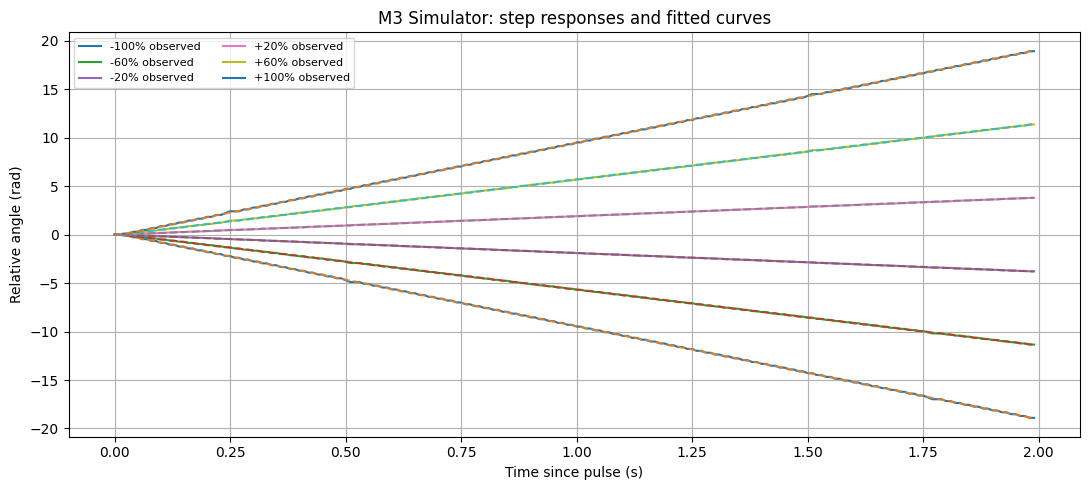

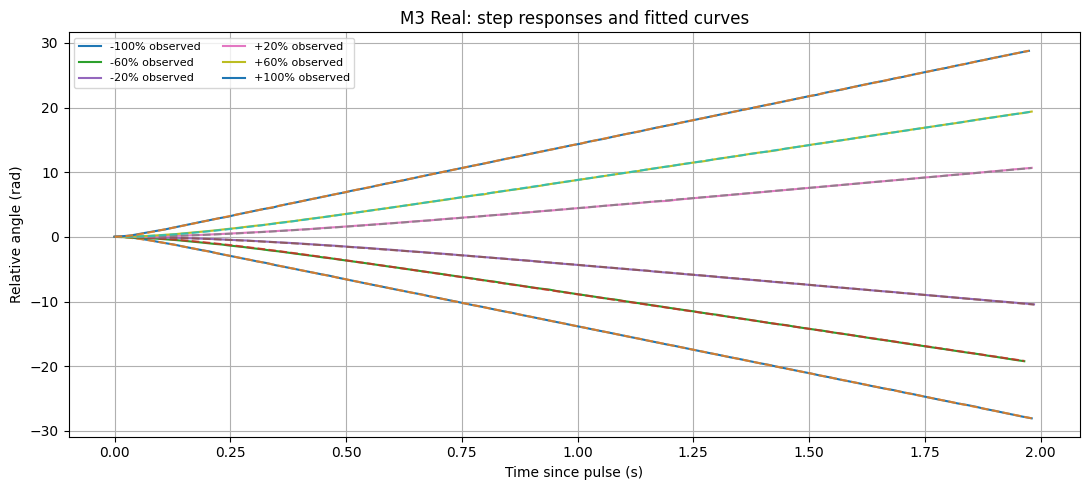

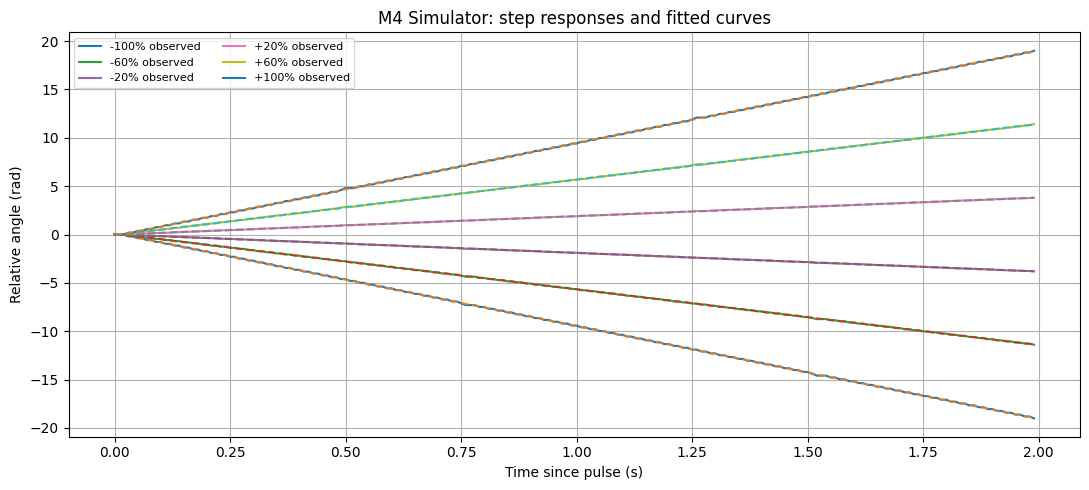

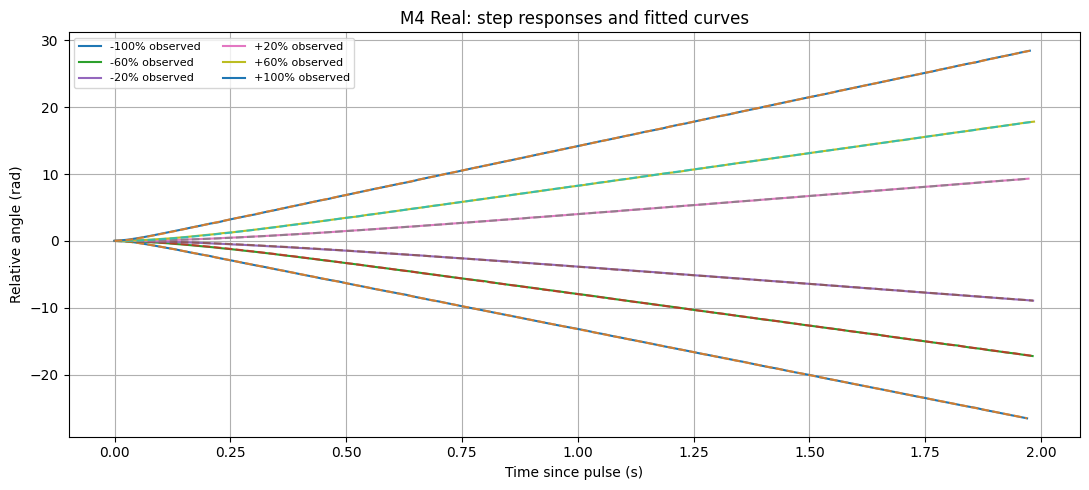

In [4]:
for (motor,env,kind),(df,traces) in fits.items():
    fig,ax=plt.subplots(figsize=(11,5))
    for pwm,t,y,yhat in traces:
        if pwm in [-100,-60,-20,20,60,100]:
            ax.plot(t,y,label=f'{pwm:+d}% observed')
            ax.plot(t,yhat,'--',alpha=.8)
    ax.set(title=f'{motor} {env}: step responses and fitted curves',xlabel='Time since pulse (s)',ylabel='Relative angle (rad)')
    ax.grid();ax.legend(ncol=2,fontsize=8);plt.tight_layout();plt.show()


## 4. Both motors on same axes: speed vs PWM and $T_m$ vs PWM

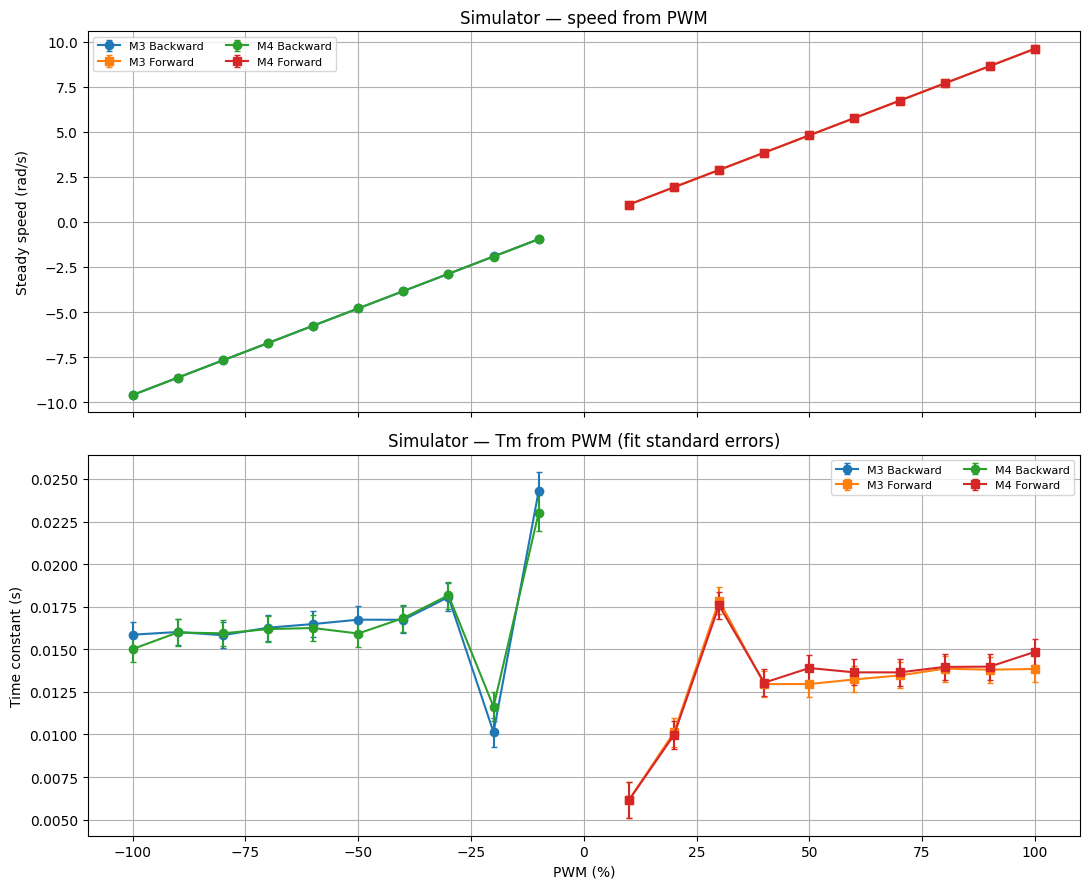

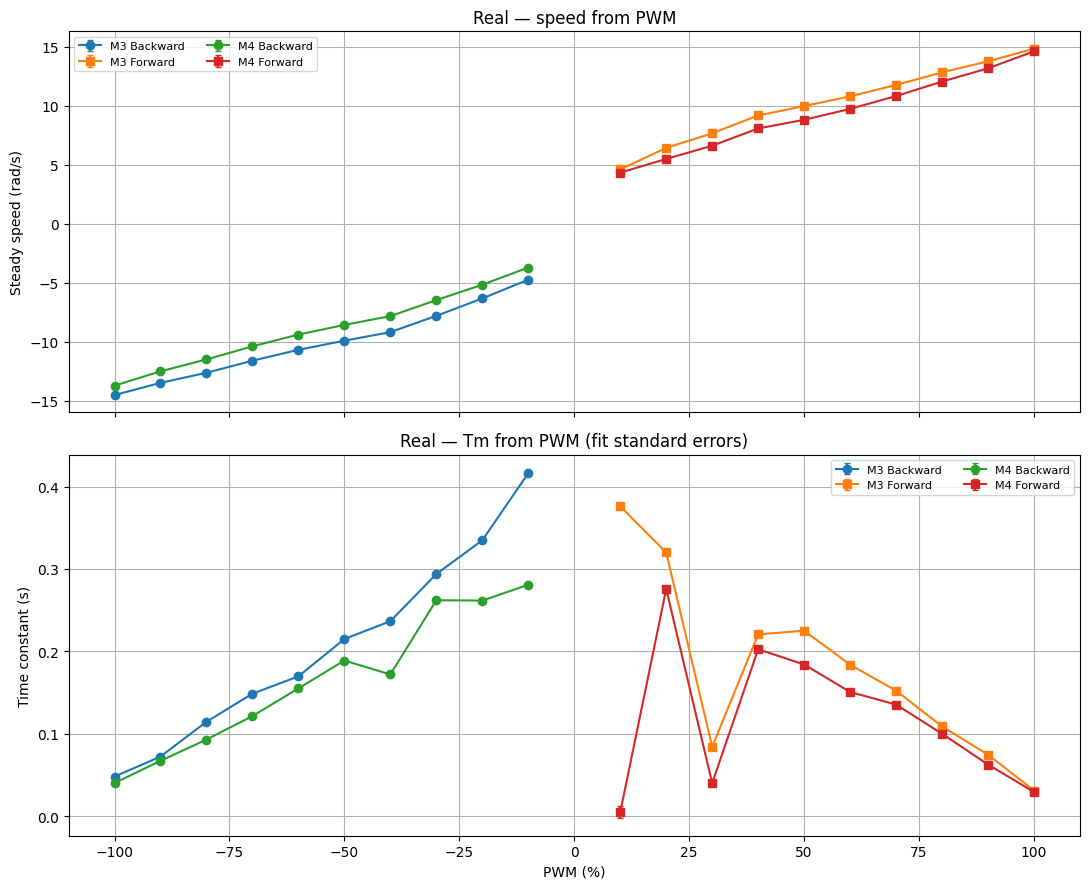

In [5]:
for env in ['Simulator','Real']:
    fig,axs=plt.subplots(2,1,figsize=(11,9),sharex=True)
    for motor in ['M3','M4']:
        df=fits[(motor,env,'A')][0]
        for direction,mask,marker in [('Backward',df.PWM<0,'o'),('Forward',df.PWM>0,'s')]:
            sub=df[mask]
            axs[0].errorbar(sub.PWM,sub.omega_ss_rad_s,yerr=sub.omega_se,fmt=marker+'-',capsize=2,label=f'{motor} {direction}')
            axs[1].errorbar(sub.PWM,sub.Tm_s,yerr=sub.Tm_se,fmt=marker+'-',capsize=2,label=f'{motor} {direction}')
    axs[0].set(title=env+' — speed from PWM',ylabel='Steady speed (rad/s)')
    axs[1].set(title=env+' — Tm from PWM (fit standard errors)',xlabel='PWM (%)',ylabel='Time constant (s)')
    for ax in axs: ax.grid();ax.legend(ncol=2,fontsize=8)
    plt.tight_layout();plt.show()

## 5. Direction-specific linear fits, indicative dead zone, and optional $k_e$

**Important:** The intercept-based dead-zone estimate is only a diagnostic approximation. Confirm it from low-PWM data. Voltage conversion requires your actual recorded battery readings; **do not invent them**.

In [ ]:
# Battery readings: 11.0 V BEFORE the experiments; 10.9 V AFTER (stationary).
voltage_before=11.0
voltage_after=10.9
voltage_drop=voltage_before-voltage_after
voltage_drop_percent=100*voltage_drop/voltage_before
# Midpoint is a representative estimate, NOT a voltage measured under load.
voltage_representative=(voltage_before+voltage_after)/2
battery_voltage={'M3':voltage_representative,'M4':voltage_representative}
print(f"Battery: before {voltage_before:.1f} V; after {voltage_after:.1f} V; change {voltage_drop:.1f} V ({voltage_drop_percent:.2f}%); representative estimate {voltage_representative:.2f} V")
# Voltage-based estimates below apply to real robot only; simulator has no measured supply voltage.
linear_rows=[]
for (motor,env,kind),(df,_) in fits.items():
    for direction in ['reverse','forward']:
        subset=df[(df.PWM<=-30) if direction=='reverse' else (df.PWM>=30)]
        slope,intercept=np.polyfit(subset.PWM,subset.omega_ss_rad_s,1)
        threshold=-intercept/slope if slope else np.nan
        V=battery_voltage[motor]
        ke=(V/100)/slope if env=='Real' and V is not None and slope else np.nan
        linear_rows.append([motor,env,direction,slope,intercept,threshold,ke])
linear=pd.DataFrame(linear_rows,columns=['Motor','Environment','Direction','speed_slope_rad_s_per_PWM','intercept_rad_s','indicative_zero_crossing_PWM','ke_V_s_per_rad'])
display(linear.round(4))
for env in ['Simulator','Real']:
    fig,ax=plt.subplots(figsize=(11,5))
    for motor in ['M3','M4']:
        df=fits[(motor,env,'A')][0]
        for direction in ['reverse','forward']:
            sub=df[df.PWM<0] if direction=='reverse' else df[df.PWM>0]
            ax.scatter(sub.PWM,sub.omega_ss_rad_s,label=f'{motor} {direction}')
            row=linear[(linear.Motor==motor)&(linear.Environment==env)&(linear.Direction==direction)].iloc[0]
            x=np.linspace(sub.PWM.min(),sub.PWM.max(),50)
            ax.plot(x,row.speed_slope_rad_s_per_PWM*x+row.intercept_rad_s,'--')
    ax.axvline(0,color='gray',lw=1);ax.axhline(0,color='gray',lw=1)
    ax.set(title=env+' — direction-specific speed calibration',xlabel='PWM (%)',ylabel='Steady speed (rad/s)')
    ax.legend(ncol=2);ax.grid();plt.tight_layout();plt.show()


## 6. Predict Program B from Program A (hold-out validation)

We interpolate the measured PWM–speed calibration and integrate a first-order speed model using median fitted $T_m$. This is an empirical model; compare with a voltage/$k_e$ formulation when battery measurements are available. At PWM changes, zero-order-hold input is used. Duplicate timestamps produce $dt=0$ and are harmless for integration.

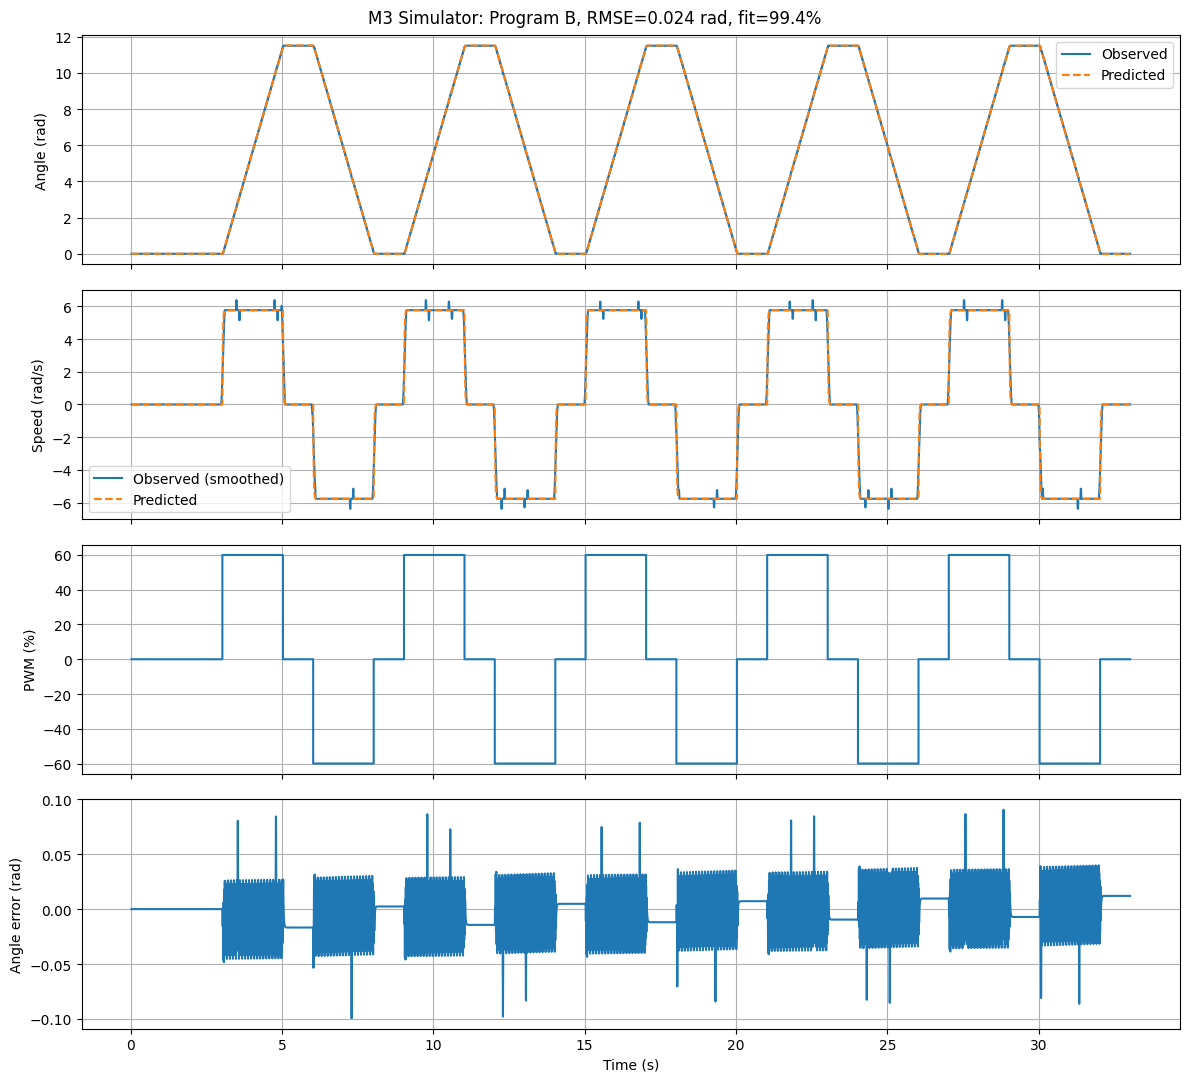

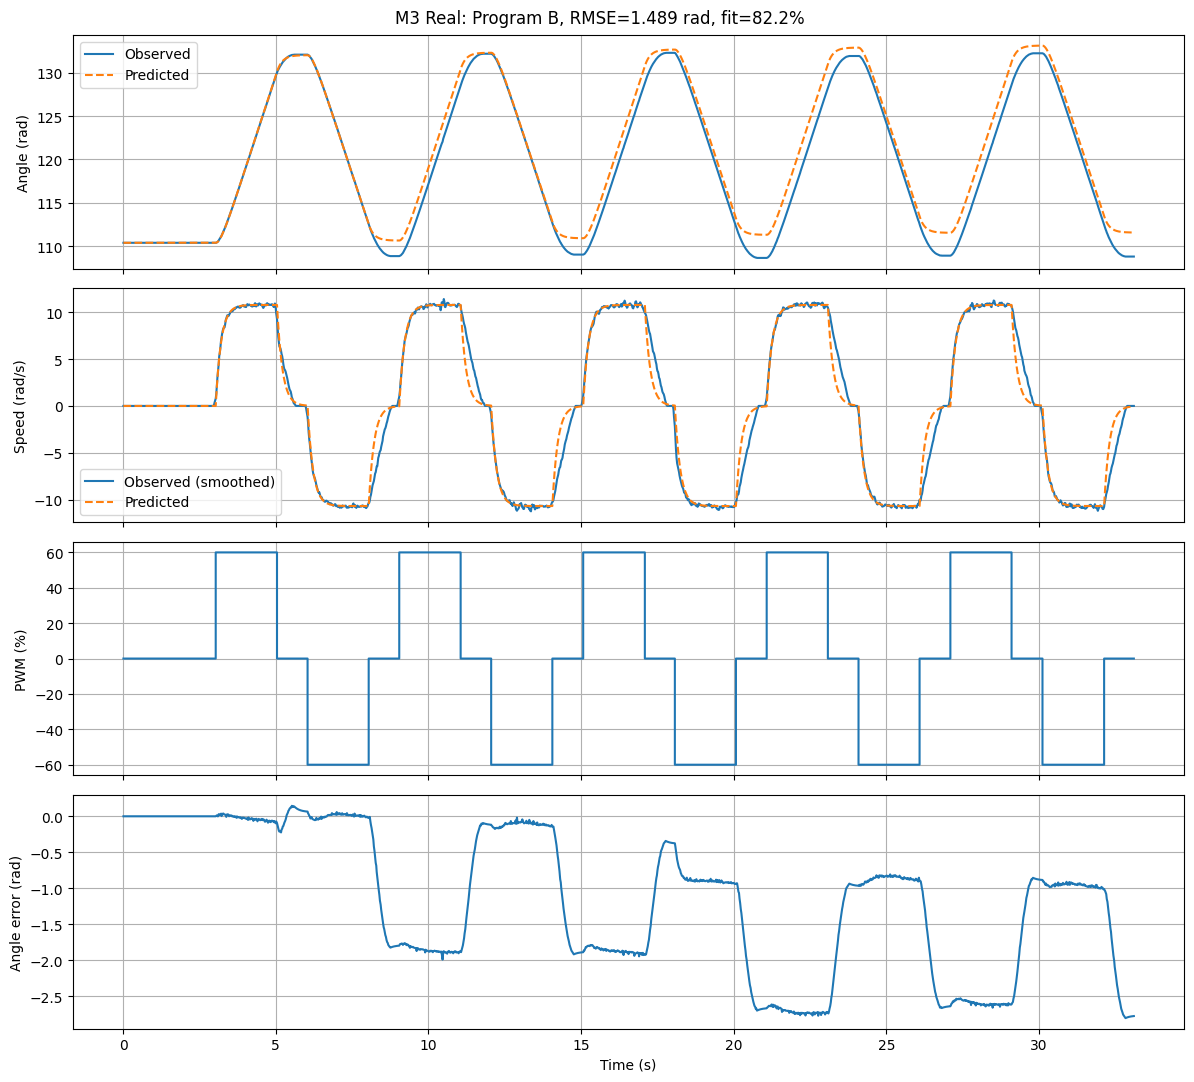

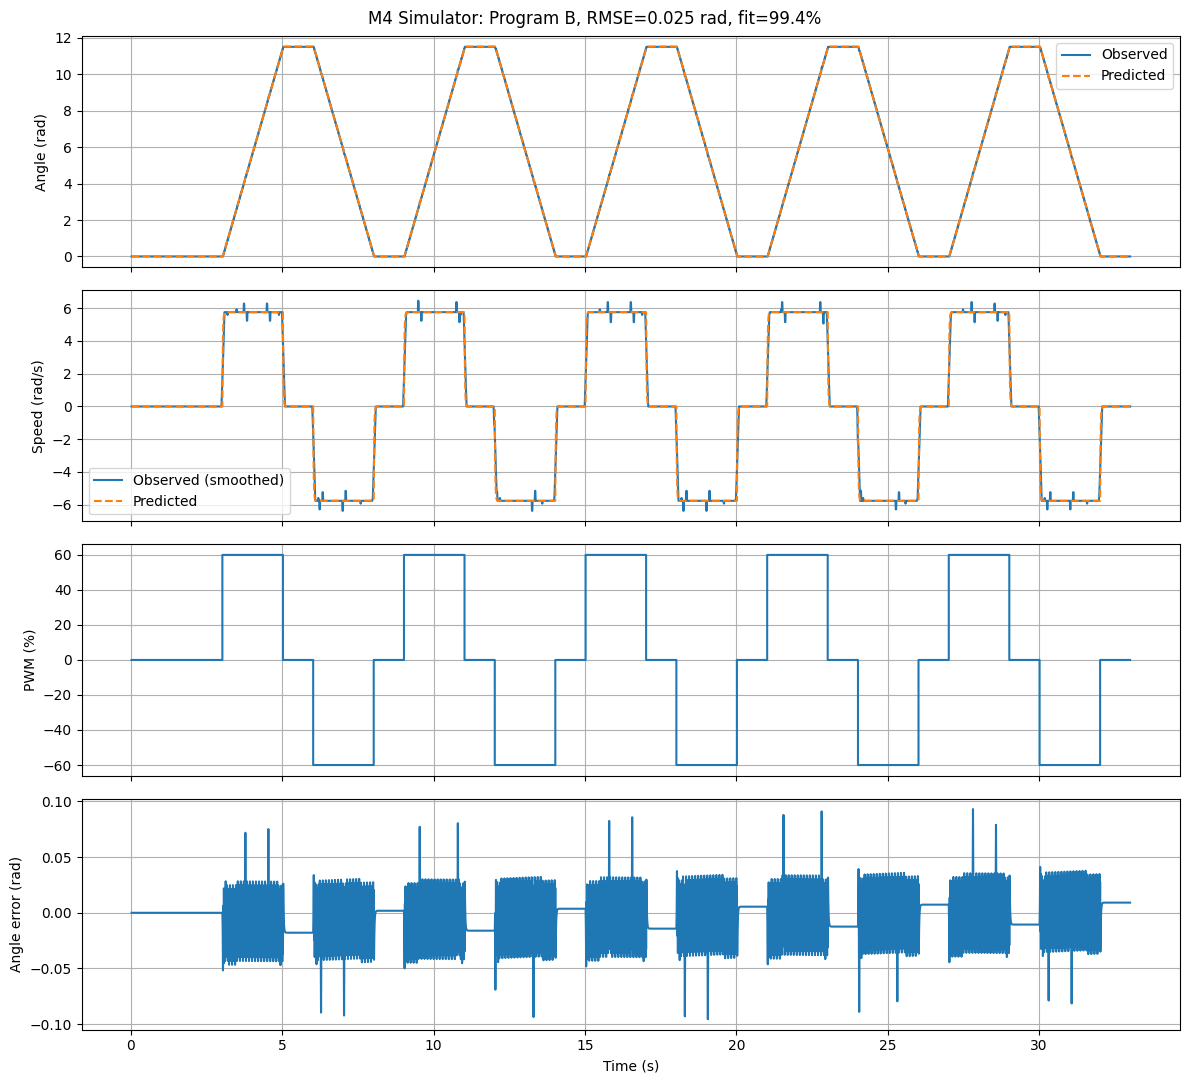

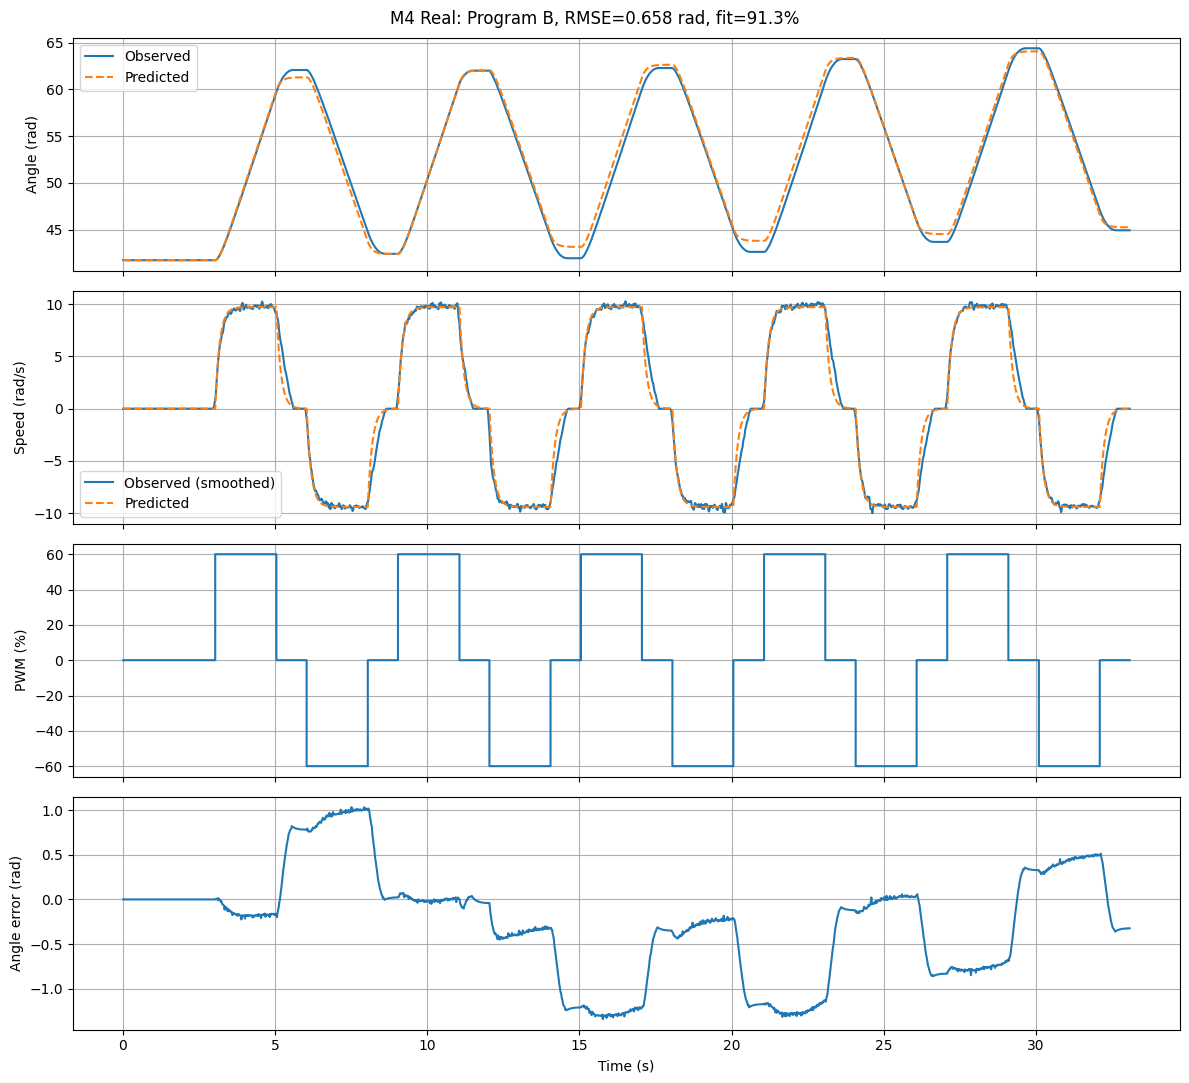

,Motor,Environment,Tm_median_s,angle_RMSE_rad,angle_fit_percent,speed_smoothing_samples
0,M3,Simulator,0.0148,0.0244,99.4471,10
1,M3,Real,0.1769,1.4889,82.1692,5
2,M4,Simulator,0.0149,0.0247,99.4403,10
3,M4,Real,0.1432,0.6578,91.3092,5


In [7]:
def predict(a,df,deadzone_pwm=0):
    t=a[:,1]/1000; p=a[:,2]
    levels=np.r_[df.PWM.to_numpy(),0]; speeds=np.r_[df.omega_ss_rad_s.to_numpy(),0]
    order=np.argsort(levels)
    ss=np.interp(p,levels[order],speeds[order]);ss[np.abs(p)<=deadzone_pwm]=0
    T=float(df.Tm_s.median());omega=np.zeros(len(t));theta=np.zeros(len(t));theta[0]=np.deg2rad(a[0,0])
    for i in range(1,len(t)):
        dt=max(0,t[i]-t[i-1]);decay=np.exp(-dt/T)
        omega[i]=omega[i-1]*decay+ss[i-1]*(1-decay)
        theta[i]=theta[i-1]+ss[i-1]*dt+(omega[i-1]-ss[i-1])*T*(1-decay)
    return t,theta,omega

summary=[]
for motor in ['M3','M4']:
    for env in ['Simulator','Real']:
        a=data[(motor,env,'B')];df=fits[(motor,env,'A')][0]
        obs=np.deg2rad(a[:,0]);t,pred,w=predict(a,df)
        # 100 ms central-difference speed estimate, robust to duplicate timestamps
        unique_t,unique_idx=np.unique(t,return_index=True)
        unique_obs=obs[unique_idx]
        raw_speed=np.gradient(unique_obs,unique_t)
        smooth_n=max(3,int(round(.1/np.median(np.diff(unique_t)))))
        smooth_speed=np.convolve(raw_speed,np.ones(smooth_n)/smooth_n,mode='same')
        speed=np.interp(t,unique_t,smooth_speed)
        rmse=np.sqrt(np.mean((obs-pred)**2))
        fitpct=100*(1-np.linalg.norm(obs-pred)/np.linalg.norm(obs-obs.mean()))
        summary.append([motor,env,df.Tm_s.median(),rmse,fitpct,smooth_n])
        fig,axs=plt.subplots(4,1,figsize=(12,11),sharex=True)
        axs[0].plot(t,obs,label='Observed');axs[0].plot(t,pred,'--',label='Predicted');axs[0].set_ylabel('Angle (rad)');axs[0].legend()
        axs[1].plot(t,speed,label='Observed (smoothed)');axs[1].plot(t,w,'--',label='Predicted');axs[1].set_ylabel('Speed (rad/s)');axs[1].legend()
        axs[2].step(t,a[:,2],where='post');axs[2].set_ylabel('PWM (%)')
        axs[3].plot(t,obs-pred);axs[3].set(xlabel='Time (s)',ylabel='Angle error (rad)')
        for ax in axs:ax.grid()
        fig.suptitle(f'{motor} {env}: Program B, RMSE={rmse:.3f} rad, fit={fitpct:.1f}%')
        plt.tight_layout();plt.show()
results=pd.DataFrame(summary,columns=['Motor','Environment','Tm_median_s','angle_RMSE_rad','angle_fit_percent','speed_smoothing_samples'])
display(results.round(4));results.to_csv('validation_results.csv',index=False)


## 7. Compare model with vs without an indicative dead zone

This threshold is **not independently validated**; it uses the speed-fit zero crossings, bounded to a plausible 0–20% range. Report whether it actually improves the hold-out RMSE.

,Motor,Environment,indicative_deadzone_PWM,RMSE_without_rad,RMSE_with_rad
0,M3,Simulator,0.0013,0.0244,0.0244
1,M3,Real,20.0000,1.4889,1.4889
2,M4,Simulator,0.0034,0.0247,0.0247
3,M4,Real,20.0000,0.6578,0.6578


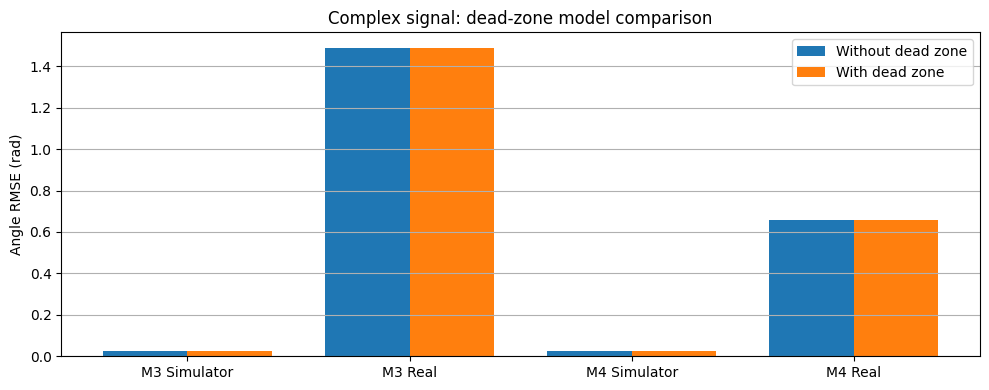

In [8]:
deadzone_rows=[]
for motor in ['M3','M4']:
    for env in ['Simulator','Real']:
        df=fits[(motor,env,'A')][0];a=data[(motor,env,'B')]
        candidate=linear[(linear.Motor==motor)&(linear.Environment==env)].indicative_zero_crossing_PWM.abs().median()
        dz=float(np.clip(candidate,0,20))
        obs=np.deg2rad(a[:,0]);_,pred0,_=predict(a,df,0);_,pred1,_=predict(a,df,dz)
        deadzone_rows.append([motor,env,dz,np.sqrt(np.mean((obs-pred0)**2)),np.sqrt(np.mean((obs-pred1)**2))])
deadzone_comparison=pd.DataFrame(deadzone_rows,columns=['Motor','Environment','indicative_deadzone_PWM','RMSE_without_rad','RMSE_with_rad'])
display(deadzone_comparison.round(4))

fig,ax=plt.subplots(figsize=(10,4))
x=np.arange(len(deadzone_comparison));width=.38
ax.bar(x-width/2,deadzone_comparison.RMSE_without_rad,width,label='Without dead zone')
ax.bar(x+width/2,deadzone_comparison.RMSE_with_rad,width,label='With dead zone')
ax.set_xticks(x,[f'{r.Motor} {r.Environment}' for _,r in deadzone_comparison.iterrows()])
ax.set(ylabel='Angle RMSE (rad)',title='Complex signal: dead-zone model comparison')
ax.legend();ax.grid(axis='y');plt.tight_layout();plt.show()

## 8. Artifacts: zero-PWM drift, coast-down, sample timing

,Motor,Environment,initial_zero_drift_deg,first_stop_coast_deg,median_dt_ms,duplicate_timestamps
0,M3,Simulator,0.0,3.0,10.0,10
1,M3,Real,0.0,118.0,20.0,0
2,M4,Simulator,0.0,6.0,10.0,10
3,M4,Real,0.0,134.0,20.0,0


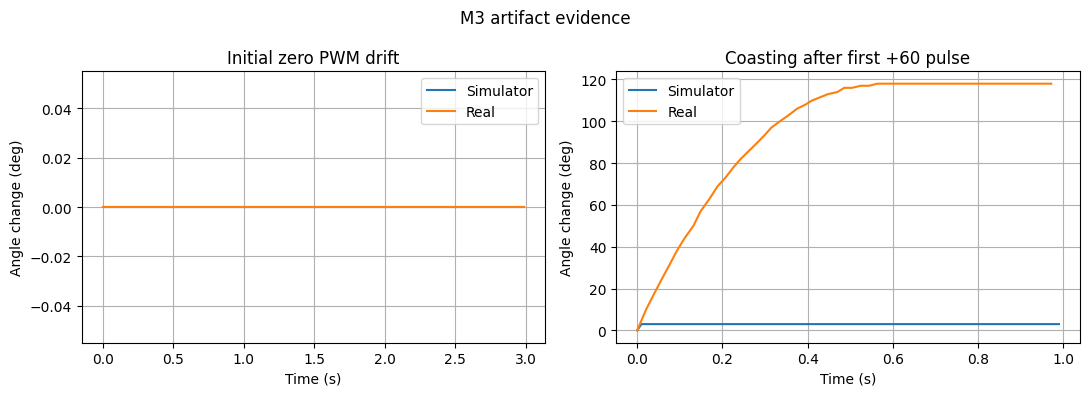

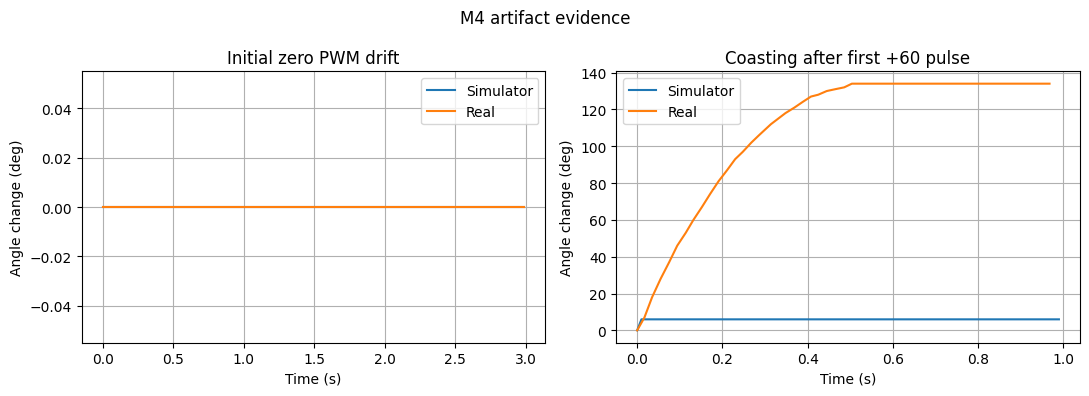

In [9]:
artifact=[]
for motor in ['M3','M4']:
    for env in ['Simulator','Real']:
        a=data[(motor,env,'B')];parts=segments(a)
        initial=parts[0][0];coast=parts[2][0]
        artifact.append([motor,env,initial[-1,0]-initial[0,0],coast[-1,0]-coast[0,0],
                         np.median(np.diff(a[:,1])),np.sum(np.diff(a[:,1])==0)])
artifacts=pd.DataFrame(artifact,columns=['Motor','Environment','initial_zero_drift_deg','first_stop_coast_deg','median_dt_ms','duplicate_timestamps'])
display(artifacts)
for motor in ['M3','M4']:
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    for env in ['Simulator','Real']:
        parts=segments(data[(motor,env,'B')]);start=parts[0][0];stop=parts[2][0]
        axs[0].plot((start[:,1]-start[0,1])/1000,start[:,0]-start[0,0],label=env)
        axs[1].plot((stop[:,1]-stop[0,1])/1000,stop[:,0]-stop[0,0],label=env)
    axs[0].set(title='Initial zero PWM drift',xlabel='Time (s)',ylabel='Angle change (deg)')
    axs[1].set(title='Coasting after first +60 pulse',xlabel='Time (s)',ylabel='Angle change (deg)')
    for ax in axs:ax.legend();ax.grid()
    fig.suptitle(motor+' artifact evidence');plt.tight_layout();plt.show()


## 9. Real M4 Program A repeatability — two independent valid runs

The newly uploaded M4 real Program A recording and the newly collected `repeat_M4.txt` both contain changing encoder readings and the full PWM sweep. This section compares the **steady-state speed** and **fitted time constant** at matching PWM levels. Encoder offsets are irrelevant to speed, since velocity is calculated from changes in angle. Differences can reflect battery discharge, load/friction, temperature, and sampling noise; no cause can be established from these files alone.

The earlier M3 repeat candidate with a constant 2575° encoder is excluded. The M4 repeat now satisfies the two-valid-run requirement.


Original rows: 3235 Repeat rows: 3210
Original duration (s): 63.15
Repeat duration (s): 63.17
Matching PWM steps: 20
Mean absolute speed difference (rad/s): 1.289
Mean absolute percentage speed difference: 14.75 %
Mean time constant, original/repeat (s): 0.1415 0.1611


,PWM,omega_ss_rad_s_original,Tm_s_original,omega_ss_rad_s_repeat,Tm_s_repeat,speed_difference_rad_s,speed_absolute_percent_difference,Tm_difference_s
0,-100,-13.7241,0.0404,-15.4145,0.0322,-1.6904,12.3173,-0.0082
1,-90,-12.5129,0.0674,-14.1097,0.0627,-1.5968,12.7614,-0.0047
2,-80,-11.5048,0.0932,-13.0032,0.1006,-1.4983,13.0234,0.0075
3,-70,-10.3929,0.1216,-11.7831,0.0906,-1.3902,13.3767,-0.0311
4,-60,-9.3972,0.1552,-10.7600,0.1600,-1.3628,14.5024,0.0048
5,-50,-8.5798,0.1890,-9.8926,0.2058,-1.3128,15.3011,0.0168
6,-40,-7.8337,0.1721,-9.0547,0.1990,-1.2210,15.5858,0.0269
7,-30,-6.4769,0.2621,-7.4528,0.2291,-0.9759,15.0674,-0.0330
8,-20,-5.1740,0.2617,-6.2787,0.2871,-1.1047,21.3512,0.0254
9,-10,-3.7190,0.2809,-4.5684,0.3209,-0.8494,22.8386,0.0400


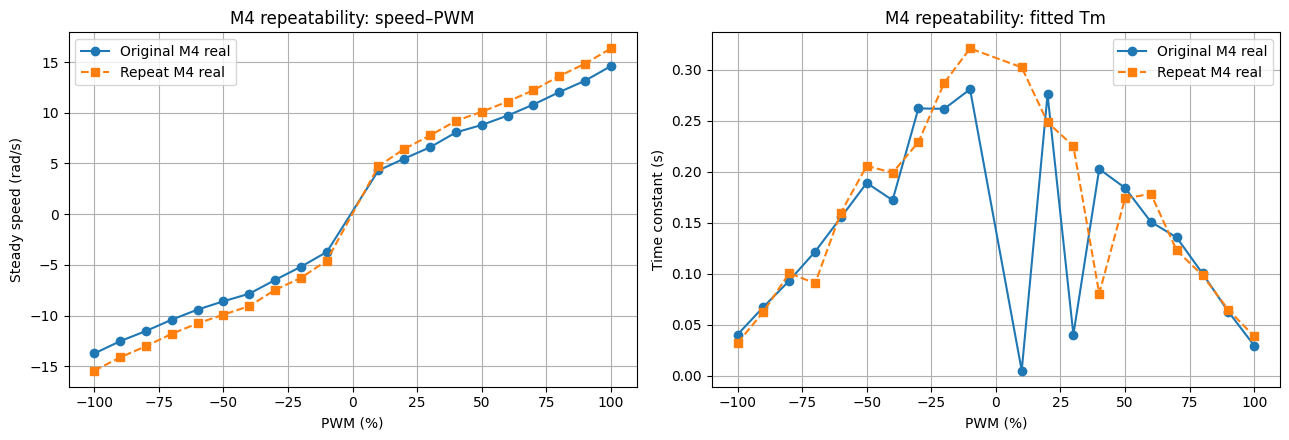

In [10]:
repeat=np.loadtxt(folder/'M4_Real_A_repeat.txt',delimiter=',')
original=data[('M4','Real','A')]
assert repeat.shape[1]==3 and np.ptp(repeat[:,0])>100, 'Repeat encoder data invalid'
assert np.all(np.diff(repeat[:,1])>0), 'Repeat timestamps must increase'
assert set(np.unique(repeat[:,2]))==set(np.unique(original[:,2])), 'PWM sweeps do not match'
repeat_fit,_=fit_steps(repeat)
reference=fits[('M4','Real','A')][0]
joined=reference[['PWM','omega_ss_rad_s','Tm_s']].merge(
    repeat_fit[['PWM','omega_ss_rad_s','Tm_s']],on='PWM',suffixes=('_original','_repeat'))
joined['speed_difference_rad_s']=joined.omega_ss_rad_s_repeat-joined.omega_ss_rad_s_original
joined['speed_absolute_percent_difference']=100*np.abs(joined.speed_difference_rad_s)/joined.omega_ss_rad_s_original.abs().replace(0,np.nan)
joined['Tm_difference_s']=joined.Tm_s_repeat-joined.Tm_s_original
print('Original rows:',len(original),'Repeat rows:',len(repeat))
print('Original duration (s):',round((original[-1,1]-original[0,1])/1000,2))
print('Repeat duration (s):',round((repeat[-1,1]-repeat[0,1])/1000,2))
print('Matching PWM steps:',len(joined))
print('Mean absolute speed difference (rad/s):',round(joined.speed_difference_rad_s.abs().mean(),3))
print('Mean absolute percentage speed difference:',round(joined.speed_absolute_percent_difference.mean(),2),'%')
print('Mean time constant, original/repeat (s):',round(joined.Tm_s_original.mean(),4),round(joined.Tm_s_repeat.mean(),4))
display(joined.round(4))
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
axs[0].plot(joined.PWM,joined.omega_ss_rad_s_original,'o-',label='Original M4 real')
axs[0].plot(joined.PWM,joined.omega_ss_rad_s_repeat,'s--',label='Repeat M4 real')
axs[0].set(xlabel='PWM (%)',ylabel='Steady speed (rad/s)',title='M4 repeatability: speed–PWM')
axs[1].plot(joined.PWM,joined.Tm_s_original,'o-',label='Original M4 real')
axs[1].plot(joined.PWM,joined.Tm_s_repeat,'s--',label='Repeat M4 real')
axs[1].set(xlabel='PWM (%)',ylabel='Time constant (s)',title='M4 repeatability: fitted Tm')
for ax in axs: ax.grid(True);ax.legend()
plt.tight_layout();plt.show()


## 10. Sampling jitter and quantization evidence

Histogram of actual time differences. Duplicate timestamps are displayed separately; angle differentiation uses unique timestamps.

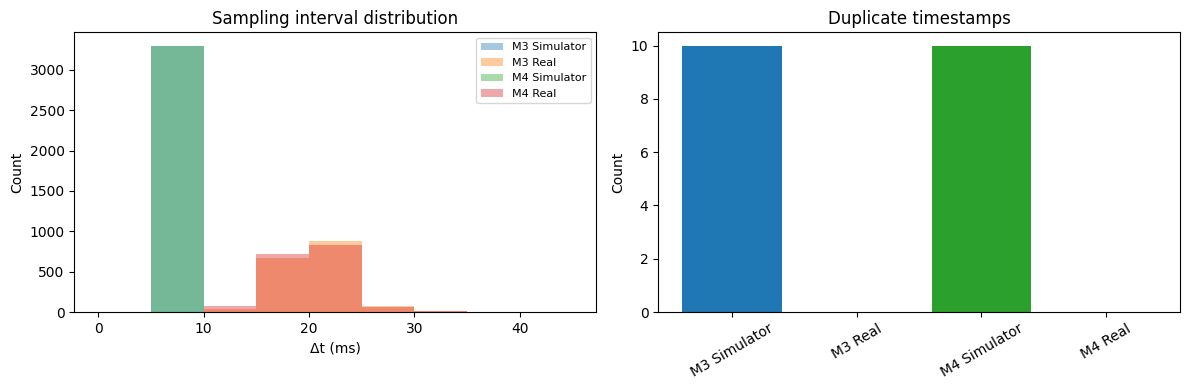

Speed is derived from encoder angles; quantization creates stair-step readings and noisy numerical derivatives.


In [11]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
for motor in ['M3','M4']:
    for env in ['Simulator','Real']:
        a=data[(motor,env,'B')]; dt=np.diff(a[:,1]); pos=dt[dt>0]
        axs[0].hist(pos,bins=np.arange(0,min(100,np.max(pos)+5),5),alpha=.4,label=f'{motor} {env}')
        axs[1].bar(f'{motor} {env}',np.sum(dt==0))
axs[0].set(title='Sampling interval distribution',xlabel='Δt (ms)',ylabel='Count');axs[0].legend(fontsize=8)
axs[1].set(title='Duplicate timestamps',ylabel='Count');axs[1].tick_params(axis='x',rotation=30)
plt.tight_layout();plt.show()
print('Speed is derived from encoder angles; quantization creates stair-step readings and noisy numerical derivatives.')

## 11. Summary tables required by the assignment

The battery was **11.0 V before** the experiments and **10.9 V immediately after**, with the robot stationary for the after-reading. The measured decrease is **0.1 V**, or **0.91%** relative to 11.0 V. No voltage was measured under motor load or for each individual run. We use the **11.0–10.9 V** measured range and its **10.95 V midpoint** only as a representative approximation: $V_{motor}\approx(PWM/100)\times10.95\,\mathrm{V}$, neglecting driver losses and voltage sag under load. Consequently the reported $k_e$ values for the **real robot** are *conditional estimates*, not independently measured physical constants. Simulator $k_e$ is left unavailable. Indicative zero crossings are **not** proven physical dead zones.


In [ ]:
for motor in ['M3','M4']:
    rows=[]
    for env in ['Simulator','Real']:
        for direction in ['forward','reverse']:
            r=linear[(linear.Motor==motor)&(linear.Environment==env)&(linear.Direction==direction)].iloc[0]
            subset=fits[(motor,env,'A')][0]
            subset=subset[subset.PWM>0] if direction=='forward' else subset[subset.PWM<0]
            rows.append([env,direction,round(abs(r.indicative_zero_crossing_PWM),2),round(r.speed_slope_rad_s_per_PWM,4),round(r.ke_V_s_per_rad,4) if env=='Real' else None,round(subset.Tm_s.mean(),4),battery_voltage[motor] if env=='Real' else None])
    print('Motor',motor)
    display(pd.DataFrame(rows,columns=['Environment','Direction','Indicative dead zone (% PWM)','Slope (rad/s per % PWM)','ke (V s/rad)','Mean Tm (s)','Representative supply (V; estimated)']))